<a href="https://colab.research.google.com/github/serraozkasap/ml-ai4i-predictive-maintenance/blob/main/ai4i_predictive_maintenance.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Based on CRISP-DM I'll follow these steps:

1. Business Understanding,
2. Data Understanding,
3. Data Preparation,
4. Modeling,
5. Evaluation,
6. Conclusions

## 1. Business Understanding

**Problem:** Unplanned machine stops break the production flow, increase costs and reduce efficiency. When a machine fails during production, the parts it is making often become scrap and the repair has to be done at the worst possible moment.

**My goal of this project:** I want to predict, from the sensor readings of a milling machine, whether it is going to fail (`Machine failure = 1`) and understand which conditions lead to a failure. If a failure can be predicted before it happens, maintenance can be planned, the machine can be stopped at a convenient time and scrap and maintenance costs go down.

**Which error is more expensive, I will focus for my interpration:**

- *Missed failure (false negative):* the model says "OK" but the machine fails. This causes an unplanned stop, scrap and possibly a damaged tool. **This is the expensive error. I'm planning to focus this one.**
- *False alarm (false positive):* the model says "failure" but the machine is fine. This causes one unnecessary inspection, which is a short and planned stop.

**Which metric will I focus on?**

- Only 3.39% of the records are failures (see Data Understanding session). A model that always predicts "no failure" would reach 96.61% accuracy and still miss every failure, so I understand that **accuracy is not a useful metric here**.
- My main metric is **recall on the failure class**: the share of real failures the model catches.
- A model that raises an alarm on every record has recall = 1 but is useless, so I also track **precision** (how many alarms are real failures).
- To compare models and choose the decision threshold I use the **F2-score**, which combines precision and recall but gives recall more weight, because a missed failure costs more than a false alarm.
- For every model I will report the confusion matrix, precision, recall, F2-score and the precision-recall curve (PR-AUC).

In [60]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [61]:
df = pd.read_csv("https://raw.githubusercontent.com/serraozkasap/ml-ai4i-predictive-maintenance/refs/heads/main/predictive-maintenance-dataset-ai4i-2020.csv") #I just want to without uploading any file by hand (Colab deletes uploaded files when the session ends).
print(df.shape) #how many row and column we have

(10000, 14)


   # 2. Data Understanding

In [62]:
df.head() #I want to see couple lines of dataset to understand how it looks like
#each row is one machine record with an ID (UDI, Product ID)-we can eliminate these ones on feature engineering part-, the product quality type (L/M/H),
#five sensor readings, the target "Machine failure" and five failure-mode flags (TWF, HDF, PWF, OSF, RNF)

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [63]:
df.info() #trying to see whole dataset data type and is there any null (it's important for accurate analysis)
#"Type" must be encoded as numbers before modeling
#"Product ID" is only an identifier

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  object 
 2   Type                     10000 non-null  object 
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Machine failure          10000 non-null  int64  
 9   TWF                      10000 non-null  int64  
 10  HDF                      10000 non-null  int64  
 11  PWF                      10000 non-null  int64  
 12  OSF                      10000 non-null  int64  
 13  RNF                      10000 non-null  int64  
dtypes: float64(3), int64(9)

In [64]:
print(df.isna().sum()) #to count the missing values per column. Missing values would have to be removed or imputed in that case we don't need imputations

UDI                        0
Product ID                 0
Type                       0
Air temperature [K]        0
Process temperature [K]    0
Rotational speed [rpm]     0
Torque [Nm]                0
Tool wear [min]            0
Machine failure            0
TWF                        0
HDF                        0
PWF                        0
OSF                        0
RNF                        0
dtype: int64


In [65]:
print("Duplicated rows:", df.duplicated().sum()) #duplicated rows lower data quality. If the same row ended up in both the training set and the
#test set, the model would be tested on data it has already seen and the test score would look.
#in that case we don't need to remove, the train/test split later will not have overlapping records

Duplicated rows: 0


In [66]:
df.describe() #I want to make plausibility check, see is the statistical metrics on our dataset like mean, std, min, quartiles and max but only for numerical columns
#it would help me to understand the range of each sensor and whether some features need scaling

#rotational speed is around 1538.78 rpm
#torque around 39.99 Nm,
#temperatures around 310 K

#all values are physically plausible so no negative values, temperatures in Kelvin around 295-314 K (make sense)

#tool wear between 0 and 253 minutes. It shows me that some of the tools didnot used before and some of them working for 253 min

#the mean of "Machine failure" is 0.0339, so only 3.39% of the records are failures. I'll mentioned it on Business Dev. part!!

#UDI only counts the rows from 1 to 10,000, so it carries no information. I'LL ELIMINATE IT ON MY DATA PREPARATION PART, NO NEED TO USE.

#distance-based and gradient-based models (KNN, logistic regression, neural networks) need scaling,
#otherwise rotational speed would dominate the other features
#tree-based models do not need scaling

,UDI,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
count,10000.00000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000
mean,5000.50000,300.004930,310.005560,1538.776100,39.986910,107.951000,0.033900,0.004600,0.011500,0.009500,0.009800,0.00190
std,2886.89568,2.000259,1.483734,179.284096,9.968934,63.654147,0.180981,0.067671,0.106625,0.097009,0.098514,0.04355
min,1.00000,295.300000,305.700000,1168.000000,3.800000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
25%,2500.75000,298.300000,308.800000,1423.000000,33.200000,53.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
50%,5000.50000,300.100000,310.100000,1503.000000,40.100000,108.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
75%,7500.25000,301.500000,311.100000,1612.000000,46.800000,162.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
max,10000.00000,304.500000,313.800000,2886.000000,76.600000,253.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.00000


In [67]:
print(df["Machine failure"].value_counts())
print(df["Machine failure"].value_counts(normalize=True) * 100) #to see how the target classes are distributed (counts and percentages)

#9,661 records without failure (96.61%) and only 339 with failure (3.39%). I'LL MENTIONED THIS ON BUSINESS DEV PART!!
#The minority class is about 28 times smaller, which shows dataset imbalanced

#so accuracy would be misleading, I'll evaluate with recall, precision and F2
#I'll also use a stratified train/test split, so both sets keep the same share of failures

Machine failure
0    9661
1     339
Name: count, dtype: int64
Machine failure
0    96.61
1     3.39
Name: proportion, dtype: float64


In [68]:
print(df["Type"].value_counts(normalize=True) * 100) #to see the distribution of the product quality types (L = low, M = medium, H = high).

#"Type" has a natural order (L < M < H), so in Data Preparation I'LL USE ORDINAL ENCODING INSTEAD OF ONE-HOT ENCODING!!

Type
L    60.00
M    29.97
H    10.03
Name: proportion, dtype: float64


In [69]:
num_cols = ["Air temperature [K]", "Process temperature [K]", "Rotational speed [rpm]", "Torque [Nm]", "Tool wear [min]"] #I keep the five sensor columns in one list, so I can reuse it for plots and for scaling later.

print("Process temp > air temp in all rows:",(df["Process temperature [K]"] > df["Air temperature [K]"]).all()) #in there I checked process heats up the machine, so the process temperature should always
#be higher than the air temperature. A row where this is false would be a measurement error. it looks like there are no implausible temperature records.

Process temp > air temp in all rows: True


In [70]:
modes = ["TWF", "HDF", "PWF", "OSF", "RNF"] #consistency check between the target and the five failure modes because according to the dataset description, "Machine failure" is 1 when at least one failure mode is 1.

mode_count = df[modes].sum(axis=1) #for each row: how many failure modes are active (0, 1, 2, ...)

#Case 1: a failure is recorded, but no failure mode explains it (false negative)
failure_without_mode = (df["Machine failure"] == 1) & (mode_count == 0)

# Case 2: a failure mode is recorded, but no failure (false positive)
mode_without_failure = (df["Machine failure"] == 0) & (mode_count > 0)

print("Failure but no mode:", failure_without_mode.sum()) #9 failures without a mode
print("Mode but no failure:", mode_without_failure.sum()) #18 modes without failure

#so 27 rows (0.27%) are inconsistent.these are label-quality issues. I'LL DECIDE HOW TO HANDLE THEM IN DATA PREPARATION!!!!

Failure but no mode: 9
Mode but no failure: 18


In [71]:
print(df.loc[mode_without_failure, modes].sum()) #to find out which failure mode appears in the 18 rows where no failure was recorded.

#18 are RNF (random failure). RNF is the only mode that is not caused by the process
#it is a random event, so it cannot be predicted from the sensor readings anyway

#I think this information only supports keeping "Machine failure" as the target and treating these rows as label noise.

TWF     0
HDF     0
PWF     0
OSF     0
RNF    18
dtype: int64


#3. Data Understanding with Visualization

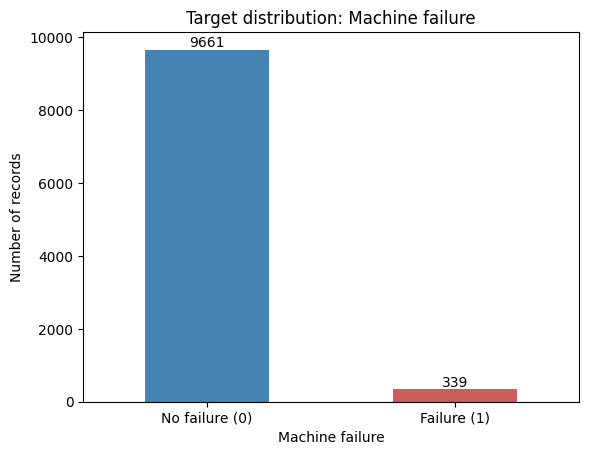

In [72]:
#I want to show the class imbalance visually (it is easier to see than a percentage, and I can use this figure in the report)
ax = df["Machine failure"].value_counts().plot(kind="bar", color=["steelblue", "indianred"])
ax.set_xticklabels(["No failure (0)", "Failure (1)"], rotation=0)
ax.set_ylabel("Number of records")
ax.set_title("Target distribution: Machine failure")
for p in ax.patches:  # write the count on top of each bar
    ax.annotate(int(p.get_height()), (p.get_x() + p.get_width() / 2, p.get_height()), ha="center", va="bottom")
plt.show()

#the "Failure" bar is tiny compared with "No failure" (339 vs 9,661)
#it confirms that accuracy is not a good metric and that I need a stratified split!!!

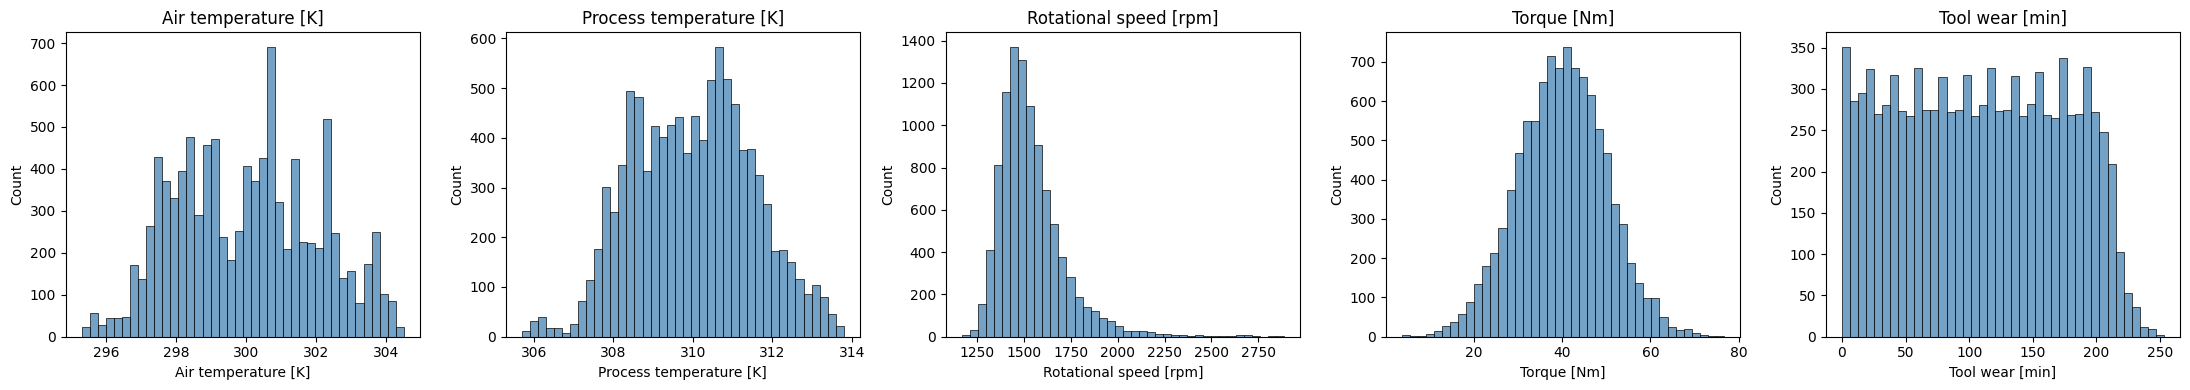

In [73]:
#I want to see the shape of each sensor's distribution (symmetric or skewed, one peak or more)
#because skewed features can need a transformation, and the shape helps me choose the scaling method
fig, axes = plt.subplots(1, 5, figsize=(22, 4))
for ax, col in zip(axes, num_cols):
    sns.histplot(df[col], bins=40, ax=ax, color="steelblue")
    ax.set_title(col)
plt.tight_layout()
plt.show()

#skewness gives one number for the asymmetry (0 = symmetric, > 1 = strongly right-skewed)

In [74]:
print(df[num_cols].skew().round(2))

#I'll put these informations to the report:
#- torque and process temperature look roughly bell-shaped and symmetric (skewness close to 0).
#- air temperature is also symmetric (skewness 0.11) but irregular, with several peaks instead of one smooth bell.
#- Tool wear is almost flat between 0 and ~200 minutes (every tool age is equally common), and very few records are above ~220 minutes.
#- Rotational speed is right-skewed (skewness 1.99): most records are around 1,400-1,600 rpm, with a long tail up to ~2,900 rpm.

#for models that are sensitive to scale I will use standardization!!!
#Because rotational speed is skewed, I can also test a log transformation in Data Preparation and compare. Tree-based models are not affected by skewness.

Air temperature [K]        0.11
Process temperature [K]    0.02
Rotational speed [rpm]     1.99
Torque [Nm]               -0.01
Tool wear [min]            0.03
dtype: float64


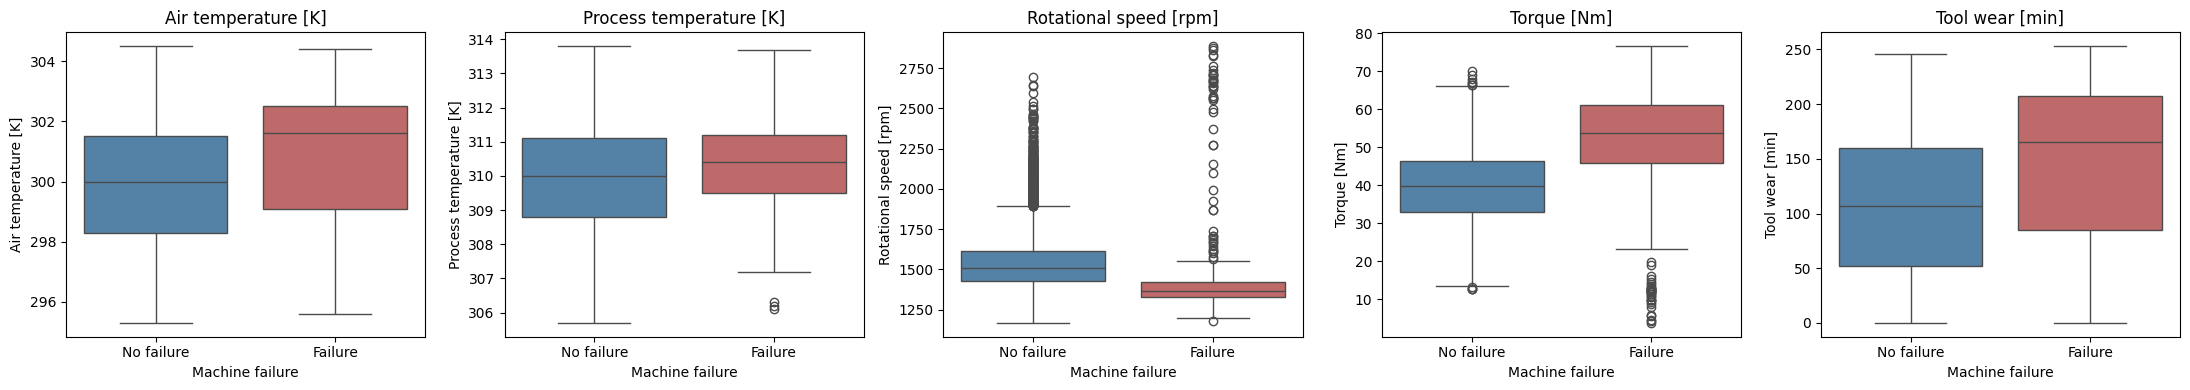

                 Air temperature [K]  Process temperature [K]  \
Machine failure                                                 
0                              300.0                    310.0   
1                              301.6                    310.4   

                 Rotational speed [rpm]  Torque [Nm]  Tool wear [min]  
Machine failure                                                        
0                                1507.0         39.9            107.0  
1                                1365.0         53.7            165.0  


In [75]:
#compare each sensor between normal records (0) and failures (1)
#if the two boxes are clearly different, the sensor is useful to predict a failure.
fig, axes = plt.subplots(1, 5, figsize=(22, 4))
for ax, col in zip(axes, num_cols):
    sns.boxplot(data=df, x="Machine failure", y=col, ax=ax, hue="Machine failure",
                palette=["steelblue", "indianred"], legend=False)
    ax.set_title(col)
    ax.set_xticks([0, 1], ["No failure", "Failure"])
plt.tight_layout()
plt.show()

#medians behind the boxes, so I can WRITE EXACT NUMBERS TO THE REPORT!!
print(df.groupby("Machine failure")[num_cols].median().round(1))

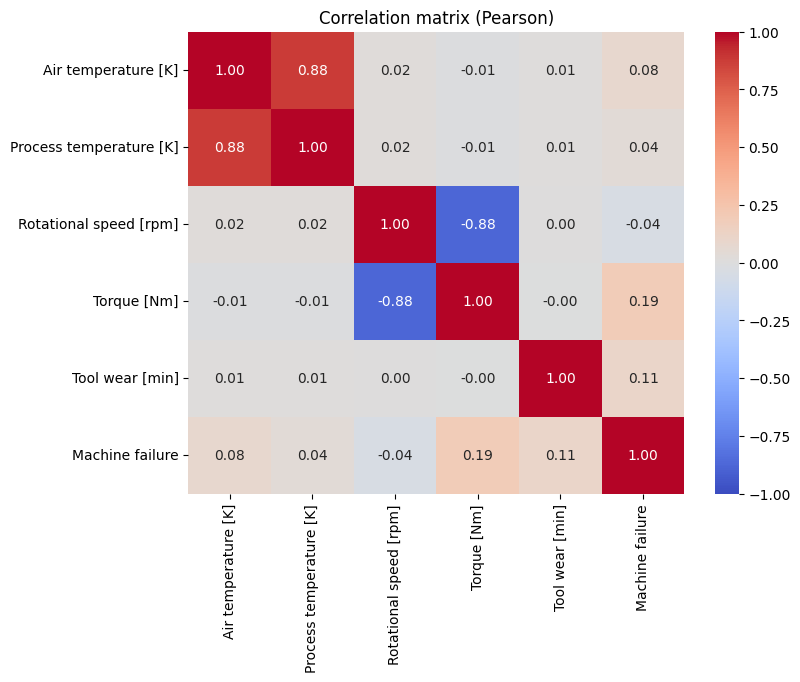

In [76]:
#I want to see which features move together. Strongly correlated features carry almost the same
#redundancy and correlation with the target shows which features matter
corr = df[num_cols + ["Machine failure"]].corr()
plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation matrix (Pearson)")
plt.show()

#I CAN USE THIS GRAPH ON PRESENTATION TO EXPLAIN CORRELATIONS!

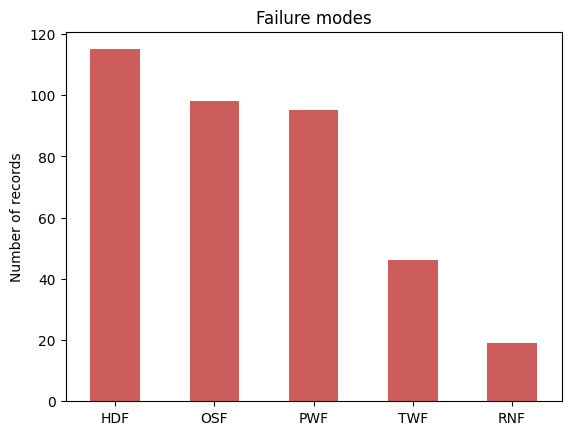

HDF    115
OSF     98
PWF     95
TWF     46
RNF     19
dtype: int64
Records with more than one failure mode: 24


In [77]:
#see which failure types are frequent. The model predicts "Machine failure" in general, but knowing which causes are common helps me explain the results.
modes_count = df[modes].sum().sort_values(ascending=False)
ax = modes_count.plot(kind="bar", color="indianred")
ax.set_ylabel("Number of records")
ax.set_title("Failure modes")
plt.xticks(rotation=0)
plt.show()
print(modes_count)

#one record can have more than one failure mode at the same time
print("Records with more than one failure mode:", (df[modes].sum(axis=1) > 1).sum())

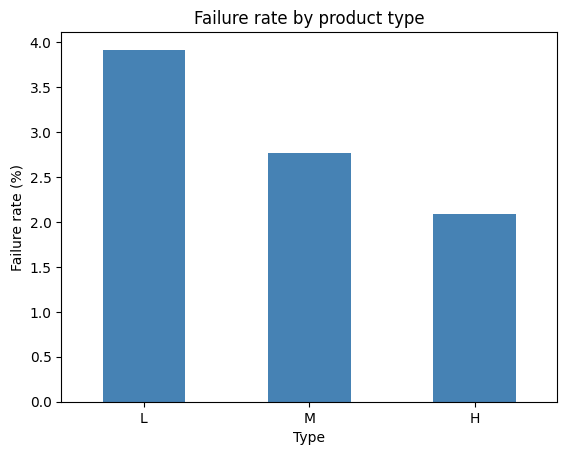

Type
L    3.92
M    2.77
H    2.09
Name: Machine failure, dtype: float64


In [78]:
#I want to check whether the product quality type (L/M/H) changes the failure rate
#mean of a 0/1 column is the share of 1s, so this gives the failure rate per type.
rate_by_type = df.groupby("Type")["Machine failure"].mean().loc[["L", "M", "H"]] * 100
ax = rate_by_type.plot(kind="bar", color="steelblue")
ax.set_ylabel("Failure rate (%)")
ax.set_title("Failure rate by product type")
plt.xticks(rotation=0)
plt.show()
print(rate_by_type.round(2))

##3.2 Outlier Analysis

I realised the box plots showed many extreme values and I couldn't be sure what to do with them so I decided to check:
1. how many outliers each sensor ha
2. whether these outliers are measurement errors or real (and important) machine conditions.

I use two methods from the course:
- the IQR rule (statistical, one feature at a time)
- Isolation Forest (looks at all sensors together).

Both are used only as a **diagnostic**: nothing is removed here.

In [79]:
#the IQR rule is the rule behind the box plot whiskers. A value is an outlier if it is:
#below Q1 - 1.5*IQR or above Q3 + 1.5*IQR. I use IQR instead of the 3-sigma rule because
#quartiles are not affected by extreme values and work also for skewed features (rotational speed)
iqr_rows = []
for col in num_cols:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    is_outlier = (df[col] < lower) | (df[col] > upper)
    iqr_rows.append({
        "feature": col,
        "lower bound": round(lower, 1),
        "upper bound": round(upper, 1),
        "n outliers": is_outlier.sum(),
        #if outliers were random measurement errors, their failure rate would be close
        #to the overall 3.39%. A much higher rate means they are linked to failures
        "failure rate among outliers (%)": round(df.loc[is_outlier, "Machine failure"].mean() * 100, 1)
                                           if is_outlier.sum() > 0 else None,
    })
pd.DataFrame(iqr_rows)

#air temperature, process temperature and tool wear have no outliers by the IQR rule
#rotational speed: 418 outliers (all above 1,896 rpm). Their failure rate is 8.4%, about 2.5 times the overall rate (3.39%)
#torque: 69 outliers (below 12.8 Nm or above 67.2 Nm), and 89.9% of them are failures

#the outliers are not noise: in torque they are almost always failures.
#removing or clipping them would delete exactly the records the model has to learn. So I keep them unchanged. But I may go back this decision after my tests. (?)

,feature,lower bound,upper bound,n outliers,failure rate among outliers (%)
0,Air temperature [K],293.5,306.3,0,NaN
1,Process temperature [K],305.4,314.6,0,NaN
2,Rotational speed [rpm],1139.5,1895.5,418,8.4
3,Torque [Nm],12.8,67.2,69,89.9
4,Tool wear [min],-110.5,325.5,0,NaN


In [80]:
#the IQR rule checks one feature at a time. Isolation Forest looks at all five ensors together and
#finds records that are easy to isolate with random cuts like unusual combinations of values

#contamination=0.03 asks it to flag the 3% most unusual records (I said 3 because I saw my anomaly looks like %3,39)
#random_state=42 makes the random cuts reproducible (this number just same as my study notes that I took my notes in this number as "usual parameter of random_state")
#because I want to compare the failure rate of the records flagged as anomalies with the rest. (-1 is anomaly, 1 is normal)

from sklearn.ensemble import IsolationForest
iso = IsolationForest(n_estimators=100, contamination=0.03, random_state=42)
is_anomaly = iso.fit_predict(df[num_cols]) == -1


print("Records flagged as anomalies:", is_anomaly.sum())
print("Failure rate among anomalies:", round(df.loc[is_anomaly, "Machine failure"].mean() * 100, 1), "%")
print("Failure rate among the others:", round(df.loc[~is_anomaly, "Machine failure"].mean() * 100, 1), "%")
print("Failures found among the anomalies:", df.loc[is_anomaly, "Machine failure"].sum(), "of", df["Machine failure"].sum())


#Isolation Forest flags 300 records. Their failure rate is 17.3%, almost six times the rate of the other records (3.0%)
#still, these 300 records contain only 52 of the 339 failures: most failures are not unusual combinations of sensor value

#this confirms the IQR result: unusual operating conditions are strongly linked to failures, so I do not remove outliers
#it also shows that anomaly detection alone is NOT ENOUGHT TO PREDICT FAILURES (it would miss about 85% of them).
#I need supervised models that learn from the failure labels, which is the next step.

#Isolation Forest is used here only as a diagnostic, on the raw sensors and without the labels, so it does not leak any information into the models.

Records flagged as anomalies: 300
Failure rate among anomalies: 17.3 %
Failure rate among the others: 3.0 %
Failures found among the anomalies: 52 of 339


#4. Data Preparation

In [81]:
#I work on a copy, so the original table df stays unchanged and I can always go back to it just in case
data = df.copy()

In [82]:
#I already decide that UDI and Product ID are only identifiers (UDI counts the rows from 1 to 10,000) so eliminate them
#because these say nothing about the machine's condition and a model could learn meaningless patterns from them
#five failure modes describe the failure itself and are only known after it happens, so using them as features would be DATA LEAKAGE (the model would "see the answer")
data = data.drop(columns=["UDI", "Product ID"] + modes)
print(data.columns.tolist())

['Type', 'Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]', 'Machine failure']


In [83]:
#I want to give the columns simple names now to avoid errors later also it's hard to write in this way
data = data.rename(columns={
    "Air temperature [K]": "air_temp",
    "Process temperature [K]": "process_temp",
    "Rotational speed [rpm]": "rotational_speed",
    "Torque [Nm]": "torque",
    "Tool wear [min]": "tool_wear",
    "Temp difference [K]": "temp_diff",
    "Power [W]": "power",
    "Machine failure": "machine_failure",
    "Type": "type",
})

In [84]:
#models only work with numbers. "Type" has a natural order (low < medium < high quality) and the failure rate goes down from L to H, so I use ORDINAL ENCODING (we saw on the class)
#one-hot encoding would create three columns and lose this order
data["type"] = data["type"].map({"L": 0, "M": 1, "H": 2})

#I want to see the result, so this one is my verification, the counts must be the same as before encoding (6,000 / 2,997 / 1,003)
print(data["type"].value_counts())

type
0    6000
1    2997
2    1003
Name: count, dtype: int64


In [85]:
#derived features. Air and process temperature (+0.88) and rotational speed and torque (-0.88)
#they are strongly correlated, and according to the dataset description two failure modes depend on a combination of them:
#- heat dissipation failure (HDF) depends on the difference between process and air temperature
#- power failure (PWF) depends on the power, which is torque x angular speed
data["temp_diff"] = data["process_temp"] - data["air_temp"]

#Power[W] = torque[Nm] x angular speed[rad/s]; rpm is converted to rad/s with 2 * pi / 60
data["power"] = data["torque"] * data["rotational_speed"] * 2 * np.pi / 60

print(data[["temp_diff","power"]].describe().round(1))

       temp_diff    power
count    10000.0  10000.0
mean        10.0   6279.7
std          1.0   1067.4
min          7.6   1148.4
25%          9.3   5561.2
50%          9.8   6271.0
75%         11.0   7003.0
max         12.1  10469.9


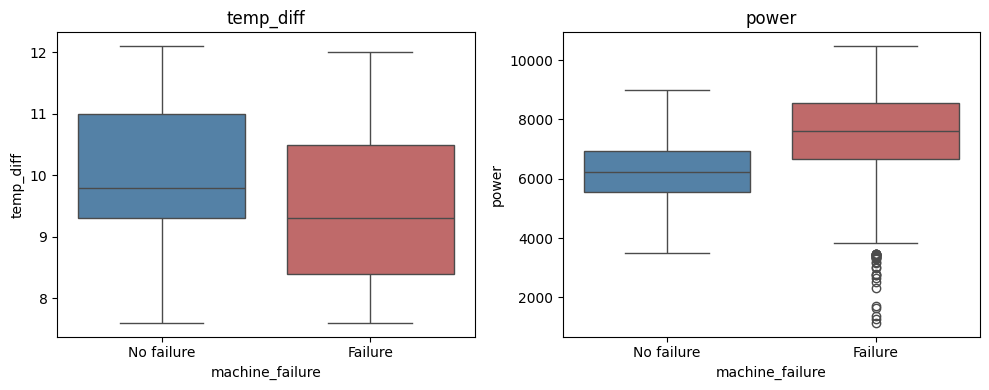

                 temp_diff   power
machine_failure                   
0                      9.8  6243.0
1                      9.3  7611.4


In [86]:
#I want to check whether the two new features really separate failures from normal records
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, col in zip(axes, ["temp_diff", "power"]):
    sns.boxplot(data=data, x="machine_failure", y=col, ax=ax, hue="machine_failure",
                palette=["steelblue", "indianred"], legend=False)
    ax.set_xticks([0, 1], ["No failure", "Failure"])
    ax.set_title(col)
plt.tight_layout()
plt.show()

print(data.groupby("machine_failure")[["temp_diff", "power"]].median().round(1))

#my comments:
#-Temperature difference: median 9.8 K without failure and 9.3 K with failure, and the failure box reaches lower values (down to about 8.4 K at the first quartile).
#many failures happen when the difference is small: the machine cannot get rid of its heat (heat dissipation failure)

#-Power:median 6,243 W without failure and 7,611 W with failure.
#All normal records stay between about 3,500 and 9,000 W,
#while failures also appear outside this range: very high power (up to ~10,500 W) and a group of very low values (below ~3,500 W)
#This matches the definition of power failure (too little or too much power)

#both features are kept as inputs.
#I also keep the original sensors, because tool wear and torque are needed for the other failure modes (tool wear failure, overstrain failure)!!!

In [87]:
#I'll separate the input features (X) from the target I want to predict (y).
X = data.drop(columns=["machine_failure"])
y = data["machine_failure"]
print("X shape:", X.shape, "| y shape:", y.shape)
print(X.columns.tolist())

#label noise decision: in Section of Data Understanding I found 27 inconsistent rows (9 failures without a failure mode, 18 RNF rows without a failure)
#they are only 0.27% of the data and I cannot know which label is correct,
#so I keep them and use "Machine failure" as it is. I MENTIONED THIS ON THE REPORT AS LIMITATIONS!!!

X shape: (10000, 8) | y shape: (10000,)
['type', 'air_temp', 'process_temp', 'rotational_speed', 'torque', 'tool_wear', 'temp_diff', 'power']


In [88]:
from sklearn.model_selection import train_test_split

#the model must be evaluated on records it has never seen, to estimate how it would work on new machines. I keep 20% of the data for the test set as a rule
#- stratify=y keeps the same share of failures (3.39%) in both sets. Without it, with so few failures, the test set could get too many or too few of them by chance.
#- random_state=42 fixes the random split, so every run gives the same sets (reproducibility).
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

#sizes of the two sets and the failure rate in each
print("Train:", X_train.shape, "| failure rate:", round(y_train.mean() * 100, 2), "%")
print("Test: ", X_test.shape, "| failure rate:", round(y_test.mean() * 100, 2), "%")
print("Failures in test set:", y_test.sum())

Train: (8000, 8) | failure rate: 3.39 %
Test:  (2000, 8) | failure rate: 3.4 %
Failures in test set: 68


## 4.1 Feature relevance

Before training, I check how much information each feature carries about the target.
Pearson correlation only measures linear relationships and rotational speed had almost zero correlation (-0.04) even though failures happen at both very low and very high speed.
Mutual information (MI) measures any kind of dependence, linear or not: MI = 0 means the feature tells nothing about the target, higher values mean more information.

                  mutual information  pearson
torque                        0.0471    0.190
power                         0.0467    0.176
rotational_speed              0.0349   -0.040
temp_diff                     0.0114   -0.111
tool_wear                     0.0100    0.099
air_temp                      0.0039    0.086
process_temp                  0.0027    0.041
type                          0.0012   -0.046


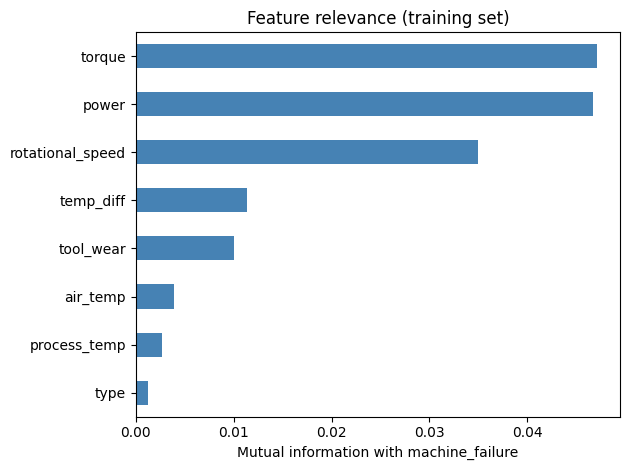

In [89]:
#I compute MI on the training set only, so the test set does not influence any decision that's why I put this code block here
#discrete_features tells the method that "type" is a category (0/1/2) and the others are continuous
#random_state=42 because the mutual information estimate uses random noise to break ties between equal values

#pearson correlation on the same training data, to compare the two measures side by side.

from sklearn.feature_selection import mutual_info_classif
mi_scores = mutual_info_classif(
    X_train, y_train,
    discrete_features=[col == "type" for col in X_train.columns],
    random_state=42)
mi = pd.Series(mi_scores, index=X_train.columns).sort_values(ascending=False)

pearson = X_train.corrwith(y_train)

relevance = pd.DataFrame({"mutual information": mi.round(4), "pearson": pearson.round(3)}).loc[mi.index]
print(relevance)

ax = mi.plot(kind="barh", color="steelblue")
ax.invert_yaxis()
ax.set_xlabel("Mutual information with machine_failure")
ax.set_title("Feature relevance (training set)")
plt.tight_layout()
plt.show()


#- torque (0.047) and power (0.047) carry the most information, followed by rotational speed (0.035)
#- rotational speed has the third highest mutual information but a Pearson correlation of only -0.04.
#this is the proof that Pearson misses non-linear (U-shaped) relationships:
#failures happen at both low and high speed, so the linear correlation cancels out, while mutual information still sees the dependence

#power is as informative as torque, and temp_diff (0.011) is more informative than air temperature (0.004) or process temperature (0.003) alone
#tool wear has a low MI (0.010) because it matters only for one failure mode (tool wear failure, 46 cases), at high wear values.
#type has the lowest MI (0.001)

#I keep all 8 features. There are only 8, and none of them has MI = 0. Removing features would bring little gain and could lose the information that some failure modes need (for example tool wear for tool wear failures).
#MI gives me the insight of ranking features and their importance

In [90]:
from sklearn.preprocessing import StandardScaler

#the features have very different scales (power almost 6,000 W vs temperature difference almost 10 K).
#distance-based and gradient-based models (KNN, logistic regression, neural networks) need scaled features; tree-based models do not, so I keep both versions
#StandardScaler transforms each feature to mean 0 and standard deviation 1.
scaler = StandardScaler()

#the scaler learns the mean and std ONLY from the training set (fit), and then applies the same values to the test set (transform)
#if I fitted it on all the data, information from the test set would leak into training and the test score would be too optimistic.
X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train), columns=X.columns, index=X_train.index)
X_test_scaled = pd.DataFrame(scaler.transform(X_test), columns=X.columns, index=X_test.index)

#in the training set every feature now has mean almost 0 and std almost 1
#the test set is close to 0 and 1, but not exactly, because it was scaled with the training values
print(X_train_scaled.describe().loc[["mean", "std"]].round(2))
print(X_test_scaled.describe().loc[["mean", "std"]].round(2))

      type  air_temp  process_temp  rotational_speed  torque  tool_wear  \
mean   0.0       0.0           0.0               0.0    -0.0       -0.0   
std    1.0       1.0           1.0               1.0     1.0        1.0   

      temp_diff  power  
mean       -0.0    0.0  
std         1.0    1.0  
      type  air_temp  process_temp  rotational_speed  torque  tool_wear  \
mean  0.04     -0.00         -0.00             -0.02   -0.01       0.02   
std   1.02      1.01          1.01              0.95    0.97       1.00   

      temp_diff  power  
mean       0.00  -0.01  
std        1.01   0.98  


I want to summarize everthing in that point for report!!

### Summary of Data Preparation

| Step | What I did | Why |
| --- | --- | --- |
| Feature selection | dropped UDI, Product ID and the five failure modes | identifiers carry no information; failure modes would be data leakage |
| Encoding | Type: L = 0, M = 1, H = 2 | ordered categories, failure rate decreases with quality |
| Derived features | temperature difference, power | linked to heat dissipation and power failures, combine strongly correlated sensors |
| Label noise | kept the 27 inconsistent rows | 0.27% of the data, correct label unknown |
| Split | 80% train (8,000), 20% test (2,000), stratified, random_state = 42 | same failure rate in both sets, reproducible |
| Scaling | StandardScaler fitted on the training set only | needed for KNN / logistic regression / neural networks; no leakage |

Final input: **8 features** (type, air_temp, process_temp, rotational_speed, torque, tool_wear, temp_diff, power). I use `X_train` / `X_test` for tree-based models and `X_train_scaled` / `X_test_scaled` for scale-sensitive models.

**Class imbalance:** I don't oversample the data here. In Modeling I will first try `class_weight="balanced"`, which tells the model that a missed failure costs more and compare it with the default.

# 5. Modeling

I am planning to train different models one by one, from the simplest to the more complex because I want to see differences. After each one I explain what I learned and why I try the next model.

**Evaluation protocol (the same for every model):**

- Every model is trained only on the training set (8,000 records, 271 failures).
- All choices (hyperparameters, class weights) are made with **5-fold stratified cross-validation on the training set**.
`The test set (2,000 records, 68 failures) is used only once per model, to report the final result. If I chose the hyperparameters by looking at the test set, the test score would become too optimistic`

- Metrics:
  * **recall** (main metric)
  * **precision**
  * **F2-score** (used to compare and select models)
  * **PR-AUC** (quality of the predicted probabilities, independent of the threshold)
  * **confusion matrix**
  * **accuracy** only as a reference
- I compare training and test results to detect **overfitting**

**Note on the size of the test set:** with 68 failures in the test set, one failure more or less changes recall by about 1.5 percentage points. Small differences between models on the test set can therefore be due to chance, which is another reason to select models with cross-validation.

In [91]:
#same 5 folds for every model, so the cross-validation results are comparable.
#StratifiedKFold keeps the failure rate (3.39%) in every fold; shuffle + random_state make it reproducible.

#f2_scorrer is my selection metric. sklearn has no ready "f2" name, so I build a scorer
#from fbeta_score with beta=2 (recall counts more than precision)
#one function that computes all my metrics, so every model is evaluated in exactly the same way.


from sklearn.metrics import (accuracy_score, precision_score, recall_score, fbeta_score, average_precision_score, confusion_matrix, make_scorer)
from sklearn.model_selection import StratifiedKFold, GridSearchCV

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
f2_scorer = make_scorer(fbeta_score, beta=2)

def evaluate(model, X, y):
    y_pred = model.predict(X)                  # predicted class (0/1) with the default threshold 0.5
    y_proba = model.predict_proba(X)[:, 1]     # predicted probability of failure
    return {
        "accuracy": accuracy_score(y, y_pred),
        "recall": recall_score(y, y_pred, zero_division=0),
        "precision": precision_score(y, y_pred, zero_division=0),
        "F2": fbeta_score(y, y_pred, beta=2, zero_division=0),
        "PR-AUC": average_precision_score(y, y_proba),
    }

#confusion matrix plot, to see the errors as numbers of machines and not only as percentages.
def plot_confusion(model, X, y, title):
    cm = confusion_matrix(y, model.predict(X))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
                xticklabels=["No failure", "Failure"], yticklabels=["No failure", "Failure"])
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.title(title)
    plt.show()

#I collect the test results of every model here, to build the final comparison table.
results = {}

## 4.1 Baseline: always predict "no failure"

Before any real model, I need a reference point. The simplest possible "model" ignores the sensors and always predicts the majority class. Every real model must clearly beat it

accuracy     0.966
recall       0.000
precision    0.000
F2           0.000
PR-AUC       0.034
dtype: float64


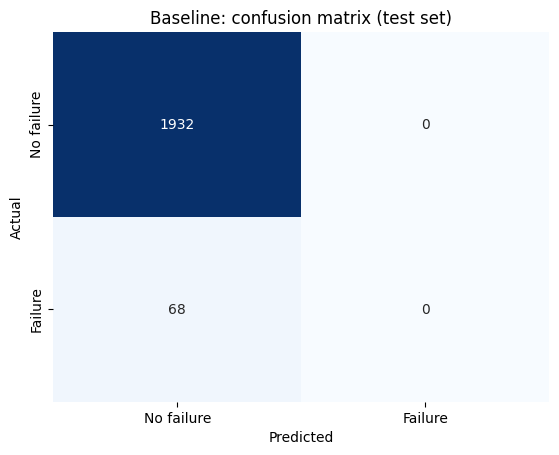

In [92]:
#strategy="most_frequent" always predicts the most common class in the training set (0 = no failure)

from sklearn.dummy import DummyClassifier

baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train, y_train)

results["Baseline (always 0)"] = evaluate(baseline, X_test, y_test)
print(pd.Series(results["Baseline (always 0)"]).round(3))
plot_confusion(baseline, X_test, y_test, "Baseline: confusion matrix (test set)")


#so the accuracy is 96.6%, but recall, precision and F2 are 0
#baseline misses all 68 failures in the test set.
#PR-AUC is 0.034, which is just the failure rate (a random guess)

#this is the numerical proof of what I wrote in Section 1: on this imbalanced dataset a useless model gets 96.6% accuracy.
#from now on accuracy is only shown for reference, and models are compared with recall, F2 and PR-AUC. I'll also mentioned this on the report because this is important.

## 4.2 Decision Tree

The decision tree is the first classifier of the course (Hunt's algorithm; scikit-learn implements CART with Gini impurity and binary splits). I start with it because:

- it can model the non-linear patterns I found in Section 2 (failures at both very low and very high speed or power) by cutting a feature at several thresholds;
- it does not need scaling, so I use the unscaled `X_train` / `X_test`;
- its rules can be read, so I can check whether they make physical sense

First I train a tree with the default settings, which grows until every leaf is pure.

In [93]:
#default settings = no depth limit, so the tree keeps splitting until every leaf contains one class
#random_state=42 similar to my previous decision of why we said 42

from sklearn.tree import DecisionTreeClassifier
dt_full = DecisionTreeClassifier(random_state=42)
dt_full.fit(X_train, y_train)

print("Depth:", dt_full.get_depth(), "| leaves:", dt_full.get_n_leaves())

#I also want to do comparing training and test results shows whether the tree memorised the training data.
comparison = pd.DataFrame({"train": evaluate(dt_full, X_train, y_train),
                           "test": evaluate(dt_full, X_test, y_test)}).round(3)
print(comparison)

#the unlimited tree has depth 17 and 108 leaves.
#on the training set every metric is 1.0 (perfect), but on the test set recall is 0.735, precision 0.758 and F2 0.740.

#perfect training score with a much lower test score is the classic sign of OVERFITTING!!!!
#the tree learned the training records by heart, including noise, instead of general rules.
#solution from the course is to limit the growth of the tree (PRUNNING!!!)
#this unlimited tree already finds about 74% of the failures, far better than the baseline, which confirms that the sensors contain a strong signal

Depth: 17 | leaves: 108
           train   test
accuracy     1.0  0.983
recall       1.0  0.735
precision    1.0  0.758
F2           1.0  0.740
PR-AUC       1.0  0.566


In [94]:
#hyperparameter tuning with grid search and 5-fold cross-validation on the training set only

#- max_depth: how deep the tree can grow (None = no limit). Smaller trees overfit less.
#- min_samples_leaf: minimum number of records in a leaf. Larger values avoid leaves built on 1-2 records.
#- class_weight: None treats both classes equally; "balanced" gives failures a weight about 28 times higher (9,661 / 339),
#missed failure costs more, like the cost matrix in the course!!!
# scoring=f2_scorer: the best combination is the one with the highest mean F2 over the 5 folds.

param_grid = {
    "max_depth": [3, 4, 5, 6, 8, 10, None],
    "min_samples_leaf": [1, 5, 10, 20],
    "class_weight": [None, "balanced"],
}
dt_search = GridSearchCV(DecisionTreeClassifier(random_state=42), param_grid,
                         scoring=f2_scorer, cv=cv)
dt_search.fit(X_train, y_train)

print("Combinations tested:", len(dt_search.cv_results_["params"]), "x 5 folds")
print("Best parameters:", dt_search.best_params_)
print("Best mean F2 in cross-validation:", round(dt_search.best_score_, 3))

#the best result for each class_weight option, to see the effect of weighting the classes.
cv_table = pd.DataFrame(dt_search.cv_results_)
cv_table["class_weight"] = cv_table["param_class_weight"].astype(str)
print(cv_table.groupby("class_weight")["mean_test_score"].max().round(3))


#56 combinations were tested.
#best one has max_depth = 10, min_samples_leaf = 1 and no class weight, with a mean cross-validated F2 of 0.773 (the unlimited tree scores 0.758 with the same procedure)
#best "balanced" tree reaches 0.753.

#limiting the depth to 10 improves the cross-validated F2, so pruning helps!!
#below I check both the selected tree and the best balanced tree on the test set, because the class weight changes the type of errors the model makes

Combinations tested: 56 x 5 folds
Best parameters: {'class_weight': None, 'max_depth': 10, 'min_samples_leaf': 1}
Best mean F2 in cross-validation: 0.773
class_weight
None        0.773
balanced    0.753
Name: mean_test_score, dtype: float64


Depth: 10 | leaves: 65
           train   test
accuracy   0.996  0.985
recall     0.908  0.706
precision  0.984  0.828
F2         0.922  0.727
PR-AUC     0.965  0.649


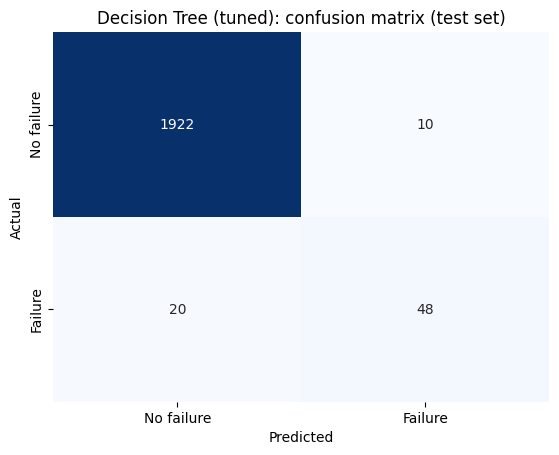

In [95]:
#best tree chosen by cross-validation (GridSearchCV retrains it on the whole training set):
dt_best = dt_search.best_estimator_
print("Depth:", dt_best.get_depth(), "| leaves:", dt_best.get_n_leaves())
print(pd.DataFrame({"train": evaluate(dt_best, X_train, y_train),
                    "test": evaluate(dt_best, X_test, y_test)}).round(3))
plot_confusion(dt_best, X_test, y_test, "Decision Tree (tuned): confusion matrix (test set)")

Best balanced parameters: {'class_weight': 'balanced', 'max_depth': None, 'min_samples_leaf': 5}
           train   test
accuracy   0.984  0.974
recall     1.000  0.809
precision  0.683  0.579
F2         0.915  0.749
PR-AUC     0.970  0.765


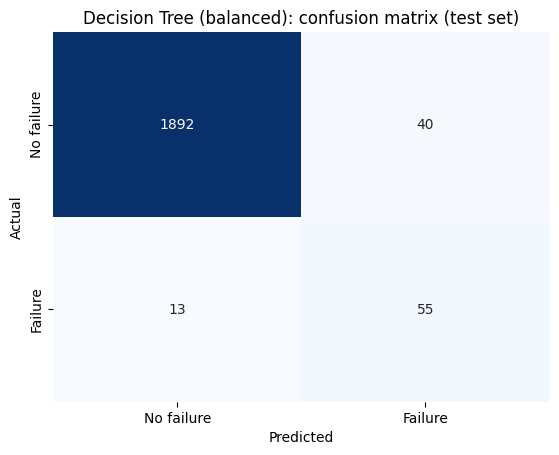

In [96]:
#best tree with class_weight="balanced", to see how weighting the failures changes the errors:
best_balanced = (cv_table[cv_table["class_weight"] == "balanced"]
                 .sort_values("mean_test_score", ascending=False).iloc[0]["params"])
print("Best balanced parameters:", best_balanced)
dt_balanced = DecisionTreeClassifier(random_state=42, **best_balanced).fit(X_train, y_train)
print(pd.DataFrame({"train": evaluate(dt_balanced, X_train, y_train),
                    "test": evaluate(dt_balanced, X_test, y_test)}).round(3))
plot_confusion(dt_balanced, X_test, y_test, "Decision Tree (balanced): confusion matrix (test set)")

In [97]:
results["Decision Tree (default)"] = evaluate(dt_full, X_test, y_test)
results["Decision Tree (tuned)"] = evaluate(dt_best, X_test, y_test)
results["Decision Tree (balanced)"] = evaluate(dt_balanced, X_test, y_test)

#I understand all of that:
#tuned tree has a smaller gap between training (F2 0.92) and test than the unlimited tree, so it overfits less.
#on the test set its F2 (0.727) is slightly lower than the unlimited tree (0.740),
#but the difference is one failure: with only 68 test failures this is within chance, and the cross-validation (which averages 5 folds) prefers the tuned tree

#balanced tree catches 8 more failures (56 instead of 48) at the cost of 31 more false alarms (41 instead of 10).
#this is exactly the recall-precision trade-off like giving failures a higher weight moves the model towards fewer missed failures and more unnecessary inspections

#I understand that which tree is better depends on the real cost ratio between a missed failure and a false alarm.
#if a missed failure costs much more than an inspection (my assumption in Section 1), the balanced tree is attractive even with more false alarms


#I will come back to this trade-off with threshold selection for the final model; class weights are one way to move it, changing the decision threshold is another!!!!

|--- power <= 9001.23
|   |--- power <= 3496.14
|   |   |--- class: 1
|   |--- power >  3496.14
|   |   |--- rotational_speed <= 1380.50
|   |   |   |--- temp_diff <= 8.55
|   |   |   |   |--- class: 1
|   |   |   |--- temp_diff >  8.55
|   |   |   |   |--- truncated branch of depth 7
|   |   |--- rotational_speed >  1380.50
|   |   |   |--- tool_wear <= 204.50
|   |   |   |   |--- truncated branch of depth 7
|   |   |   |--- tool_wear >  204.50
|   |   |   |   |--- truncated branch of depth 7
|--- power >  9001.23
|   |--- class: 1



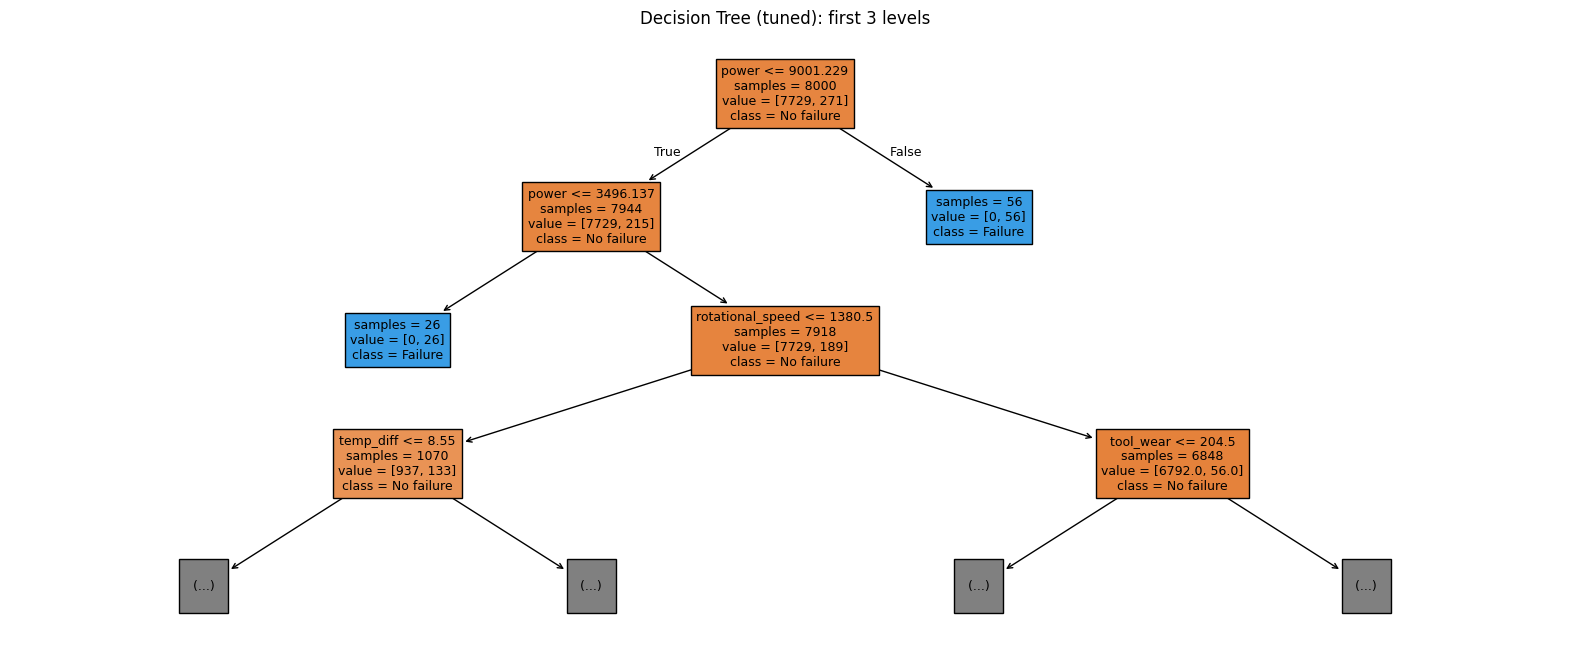

power               0.386
temp_diff           0.293
tool_wear           0.133
rotational_speed    0.077
torque              0.050
type                0.042
process_temp        0.014
air_temp            0.006
dtype: float64


In [98]:
#main advantage of a tree is that its rules can be read. I print the first levels of the tuned tree to check whether they make physical sense.

from sklearn.tree import plot_tree, export_text
print(export_text(dt_best, feature_names=list(X_train.columns), max_depth=3))

plt.figure(figsize=(20, 8))
plot_tree(dt_best, max_depth=3, feature_names=X_train.columns, class_names=["No failure", "Failure"],
          filled=True, impurity=False, proportion=False, fontsize=9)
plt.title("Decision Tree (tuned): first 3 levels")
plt.show()

#feature importance: how much each feature reduces the Gini impurity over all the splits
importance = pd.Series(dt_best.feature_importances_, index=X_train.columns).sort_values(ascending=False)
print(importance.round(3))

##I'LL USE THIS GRAPH ON REPORT!!!!

------- what I understand from the graph:-------

the first splits of the tree are almost exactly the failure definitions of the dataset, found by the tree **without ever seeing the failure-mode columns**:

- **power <= 3,496 W -> failure** and **power > 9,001 W -> failure**: this is power failure (PWF), which happens when the power is below 3,500 W or above 9,000 W. These two leaves are completely pure: they contain 26 + 56 = 82 training records, all failures (30% of the 271 training failures) and no normal record.

- **rotational_speed <= 1,380 rpm and temp_diff <= 8.55 K -> failure**: this is heat dissipation failure (HDF), which happens when the temperature difference is below 8.6 K and the speed is below 1,380 rpm.

- **tool_wear > 204.5 min** opens the branch of tool wear failure (TWF), which happens between 200 and 240 minutes.

Feature importance: **power 0.386, temp_diff 0.293, tool_wear 0.133**, rotational_speed 0.077, torque 0.050, type 0.042, the two raw temperatures below 0.02.

------- my internal comments based on these data that I saw:-------

- two derived features I created in Data Preparation (power and temp_diff) are the two most important features of the model: the feature engineering was the most useful step so far.

- Because the tree recovers the physical failure rules, I can trust that it learned real patterns and not noise. This also explains why the tree works well here: the failures are defined by thresholds, and thresholds are exactly what a tree learns.

- The remaining errors are mostly failures that no threshold explains: random failures (RNF) and the 9 failures without a failure mode found in Section 2.

In [99]:
#I'll run a comparison table, updated after every model to see differences of the models:
pd.DataFrame(results).T.round(3)

,accuracy,recall,precision,F2,PR-AUC
Baseline (always 0),0.966,0.000,0.000,0.000,0.034
Decision Tree (default),0.983,0.735,0.758,0.740,0.566
Decision Tree (tuned),0.985,0.706,0.828,0.727,0.649
Decision Tree (balanced),0.974,0.809,0.579,0.749,0.765


##4.3 K-Nearest Neighbors (KNN)

In Lecture we learnt KNN works in a completely different way from the tree. It does not build a model: it stores the training records and for a new record, looks at the k most similar records (smallest distance) and predicts the class most of them have.
In this project the question becomes: "Do the sensor values of this machine look like the values of machines that failed?"

Three things make KNN interesting here:

1. it depends on distances: so it is the first model that needs the scaled data. I can test the scaling decision from Data Preparation directly.
2. the choice of k: decides how local the decision is and I'll give this k value. I'll see the differences
3. the imbalance: with only 3.4% failures, most neighbours of any record are normal machines, so a majority vote tends to predict "no failure".


In [100]:
#the same KNN (k = 5, I gave this number by default value similar to Data Mining class) trained once on the original features and once on the scaled features
#if my reasoning in Data Preparation is right, the scaled version should be better,
#because without scaling the features with large values (power 6,000 W, rotational speed 1,500 rpm) dominate the distance
#and the small ones (temp_diff 10 K, type 0-2) are almost ignored. Similar to our example on the class for age and salary

from sklearn.neighbors import KNeighborsClassifier

knn_unscaled = KNeighborsClassifier(n_neighbors=5).fit(X_train, y_train)
knn_scaled = KNeighborsClassifier(n_neighbors=5).fit(X_train_scaled, y_train)

print(pd.DataFrame({
    "unscaled (test)": evaluate(knn_unscaled, X_test, y_test),
    "scaled (test)": evaluate(knn_scaled, X_test_scaled, y_test),
}).round(3))

#k = 5, test set:with scaling: test set has 68 failures.
#unscaled: 0,279*68=19
#scaled: 0,338*68=23 so recall shows us when we scale model caught 23 failures rather than 19.
#PR-AUC from 0.409 to 0.533
#precision stays high in both cases (about 0.97)

#this is the numerical proof of the scaling decision
#from now on KNN always uses `X_train_scaled` / `X_test_scaled` but even scaled, KNN with k = 5 catches only about one third of the failures,
#much less than the decision tree (about 70%). MAYBE OVERFIT BECAUSE I REMEMBER K=1 IS GIVING OVERFIT? ALSO I REMEMBER IF A NEIGHBOUR IS CLOSE THEIR EFFECT HAS TO BE BIGGER!

           unscaled (test)  scaled (test)
accuracy             0.974          0.976
recall               0.279          0.338
precision            0.905          0.885
F2                   0.324          0.386
PR-AUC               0.409          0.533


Best parameters: {'n_neighbors': 1, 'weights': 'uniform'} | CV F2: 0.479


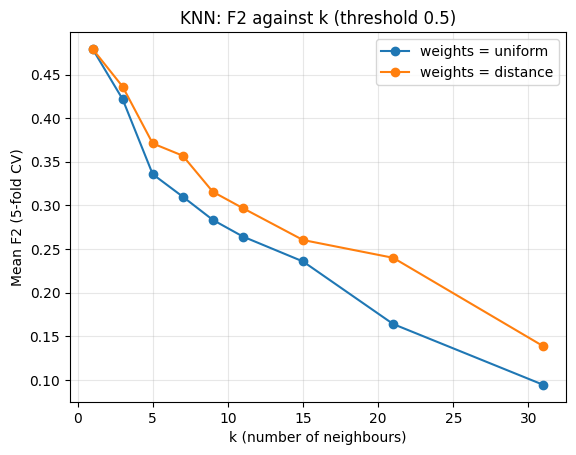

           train   test
accuracy     1.0  0.968
recall       1.0  0.456
precision    1.0  0.534
F2           1.0  0.470
PR-AUC       1.0  0.262


In [101]:
#choose k and the voting rule with 5-fold cross-validation on the training set, using F2 as in the decision tree
#weights= "uniform": every neighbour has one vote
#weights= "distance": closer neighbours have a bigger vote (weight = 1 / distance) IN THAT PART EXACTLY I AM TRYING TO PUT THIS CLOSE NEIGHBOUR EFFECT MUCH
knn_search = GridSearchCV(KNeighborsClassifier(),
                          {"n_neighbors": [1, 3, 5, 7, 9, 11, 15, 21, 31],
                           "weights": ["uniform", "distance"]},
                          scoring=f2_scorer, cv=cv)
knn_search.fit(X_train_scaled, y_train)
print("Best parameters:", knn_search.best_params_, "| CV F2:", round(knn_search.best_score_, 3))

#plot the cross-validated F2 against k, to see how the size of the neighbourhood changes the result and trying to find best K
knn_cv = pd.DataFrame(knn_search.cv_results_)
for w in ["uniform", "distance"]:
    part = knn_cv[knn_cv["param_weights"] == w]
    plt.plot(part["param_n_neighbors"], part["mean_test_score"], marker="o", label=f"weights = {w}")
plt.xlabel("k (number of neighbours)")
plt.ylabel("Mean F2 (5-fold CV)")
plt.title("KNN: F2 against k (threshold 0.5)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

#for sure the best k is 1, we saw on the group because it will create unique group of every dot on the whole universe
#but I remembered this is overfitting!!! so I check training against test to see whether it simply memorises the data
knn_1 = knn_search.best_estimator_
print(pd.DataFrame({"train": evaluate(knn_1, X_train_scaled, y_train),
                    "test": evaluate(knn_1, X_test_scaled, y_test)}).round(3))

Try to read this graph: I CAN ADD THIS ON MY PRESENTATION!!!

- the cross-validated F2 is highest with **k = 1 (0.479)** and drops steadily as k grows: 0.34-0.37 with k = 5 and **below 0.15 with k = 31**. Distance weighting helps a little for every k above 1, but does not change the trend.
- the k = 1 model is perfect on the training set (every record is its own nearest neighbour) and reaches only F2 = 0.47 on the test set: like the unlimited tree, **it memorises the training data** (the same effect I saw in the Weka lab of data mining class so I was expecting exactly this).

**why does F2 fall when k grows?** This is the imbalance problem. With k = 31, a record is predicted as a failure only if at least 16 of its 31 neighbours are failures. Failures are only 3.4% of the data, so this almost never happens, even near real failures. A larger neighbourhood is more stable but is dominated by the majority class.

the problem is not k itself but the **decision rule**. A majority vote (probability >= 0.5) is too strict for a rare class. KNN has no `class_weight` option, so the way to tell it that a missed failure is expensive is to **lower the decision threshold**: predict a failure when even a small share of the neighbours are failures. I test this next

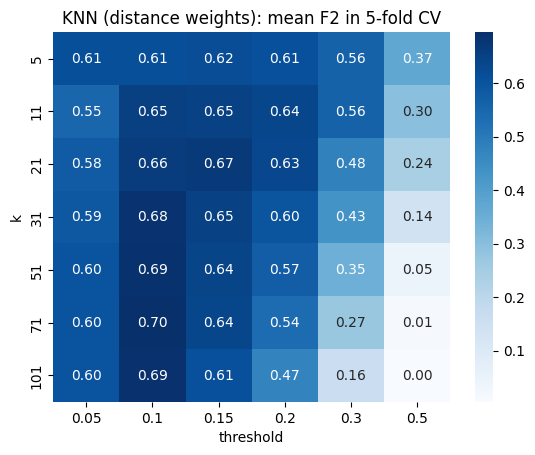

k            71.000
threshold     0.100
recall        0.790
precision     0.470
F2            0.695
Name: 31, dtype: float64


In [102]:
#predict_proba of KNN = the (weighted) share of failures among the k neighbours
#instead of the fixed threshold 0.5, I try several thresholds together with several values of k because of previous trial result
#cross_val_predict gives, for every training record, the probability predicted by a model that did NOT see that record (the record is in the validation fold),
#so the choice is made without touching the test set

from sklearn.model_selection import cross_val_predict

k_values = [5, 11, 21, 31, 51, 71, 101]
thresholds = [0.05, 0.10, 0.15, 0.20, 0.30, 0.50]
rows = []
for k in k_values:
    proba_cv = cross_val_predict(KNeighborsClassifier(n_neighbors=k, weights="distance"),
                                 X_train_scaled, y_train, cv=cv, method="predict_proba")[:, 1]
    for t in thresholds:
        pred_cv = (proba_cv >= t).astype(int)
        rows.append({"k": k, "threshold": t,
                     "recall": recall_score(y_train, pred_cv),
                     "precision": precision_score(y_train, pred_cv, zero_division=0),
                     "F2": fbeta_score(y_train, pred_cv, beta=2)})
knn_thr = pd.DataFrame(rows)

#a heatmap shows the whole k x threshold grid at once
sns.heatmap(knn_thr.pivot(index="k", columns="threshold", values="F2"),
            annot=True, fmt=".2f", cmap="Blues")
plt.title("KNN (distance weights): mean F2 in 5-fold CV")
plt.show()

best_knn = knn_thr.sort_values("F2", ascending=False).iloc[0]
print(best_knn.round(3))

- with the usual threshold 0.5 (last column), F2 collapses as k grows, as before (from 0.37 with k = 5 to 0.00 with k = 101)
- with a **low threshold (0.10)** : F2 goes up to about **0.69** for k between 31 and 101.
  - the best combination is **k = 71 with threshold 0.10**:
    - recall 0.79
    - precision 0.47 in cross-validation

- for k between 31 and 101 the F2 stays almost the same (0.685-0.695), so the exact k does not matter much once the threshold is right. I keep k = 71 because it has the highest CV score, and I note that the result is stable around it.

the decision threshold had a much bigger effect than k (F2 from 0.48 to 0.69). This is an important lesson for the next models: on imbalanced data the default threshold of 0.5 is rarely the right one. I will use the same threshold analysis for the final model!!

accuracy     0.954
recall       0.735
precision    0.400
F2           0.630
PR-AUC       0.579
dtype: float64


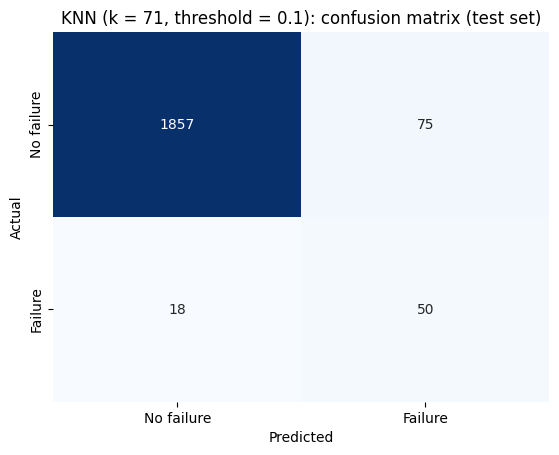

In [103]:
#train the selected KNN (k = 71, distance weights) on the whole training set and apply the threshold chosen in cross-validation (0.10) to the test set.
#this is the only time KNN sees the test set.

knn_best_k = int(best_knn["k"])
knn_best_t = float(best_knn["threshold"])
knn_final = KNeighborsClassifier(n_neighbors=knn_best_k, weights="distance").fit(X_train_scaled, y_train)

#evaluate() uses the default threshold 0.5, so here I compute the metrics with the chosen threshold
def evaluate_at_threshold(model, X, y, threshold):
    y_proba = model.predict_proba(X)[:, 1]
    y_pred = (y_proba >= threshold).astype(int)
    return {
        "accuracy": accuracy_score(y, y_pred),
        "recall": recall_score(y, y_pred, zero_division=0),
        "precision": precision_score(y, y_pred, zero_division=0),
        "F2": fbeta_score(y, y_pred, beta=2, zero_division=0),
        "PR-AUC": average_precision_score(y, y_proba),
    }, confusion_matrix(y, y_pred)

knn_test, knn_cm = evaluate_at_threshold(knn_final, X_test_scaled, y_test, knn_best_t)
print(pd.Series(knn_test).round(3))

sns.heatmap(knn_cm, annot=True, fmt="d", cmap="Blues", cbar=False,
            xticklabels=["No failure", "Failure"], yticklabels=["No failure", "Failure"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title(f"KNN (k = {knn_best_k}, threshold = {knn_best_t}): confusion matrix (test set)")
plt.show()

results[f"KNN (k={knn_best_k}, threshold {knn_best_t})"] = knn_test

**what I see from the (test set):** the final KNN catches **50 of 68 failures (recall 0.735)** but raises **75 false alarms (precision 0.40)**. F2 is **0.630** and PR-AUC **0.579**.

(on the training set this model looks perfect, but this is not a useful check here: with distance weights each training record is its own neighbour at distance 0 and decides its own vote. The cross-validation results above are the honest estimate.)

**Comparison with the decision tree:** the balanced tree catches more failures (56) with fewer false alarms (41), and its F2 (0.759) and PR-AUC (0.776) are clearly higher.

**why is KNN weaker here?**

- the failures are defined by **sharp thresholds** on single features (power below 3,500 W, temp_diff below 8.6 K, tool wear above 200 min).
  - tree learns such thresholds directly; KNN only measures how close records are and near a threshold normal and failing machines can be very close to each other.
- KNN gives **every feature the same importance** in the distance. Features with little information (type, air temperature) still add to the distance and blur it (in the Lecture we saw this situation as irrelevant attributes hurt KNN and we experienced it in here).
- it is also slower at prediction time: every new record is compared with all 8000 training records.

KNN is kept as a comparison, not as a candidate for the final model. The most useful result of this section is the threshold analysis.

In [104]:
#running comparison table after best decision of k=71 in KNN
pd.DataFrame(results).T.round(3)

,accuracy,recall,precision,F2,PR-AUC
Baseline (always 0),0.966,0.000,0.000,0.000,0.034
Decision Tree (default),0.983,0.735,0.758,0.740,0.566
Decision Tree (tuned),0.985,0.706,0.828,0.727,0.649
Decision Tree (balanced),0.974,0.809,0.579,0.749,0.765
"KNN (k=71, threshold 0.1)",0.954,0.735,0.400,0.630,0.579


## 4.4 Naive Bayes

Bayes is a probabilistic classifier for each record it computes the probability of each class with Bayes statistical theorem and predicts the more probable one:

$$P(\text{failure} \mid x) \propto P(\text{failure}) \cdot \prod_i P(x_i \mid \text{failure})$$

- **P(failure)** is the **prior**: the share of failures in the training set (3.39%).
- **P(x_i | failure)** is the **likelihood** of each feature value among failures. In Naive Bayes each feature is described, separately for each class, by one normal distribution with its own mean and variance.
- it is "naive" because it assumes that the features are **independent given the class**, so their likelihoods can simply be multiplied.

I try it because it handles the rare class in a different way from the tree and KNN: through the prior. It is also very fast and needs little data. The question is how much its two assumptions (normal distributions, independent features) hurt on this dataset.

Naive Bayes is not distance-based, so scaling does not change its predictions; I use the unscaled `X_train` / `X_test`.


Priors [no failure, failure]: [0.9661 0.0339]
           train   test
accuracy   0.960  0.961
recall     0.413  0.294
precision  0.407  0.400
F2         0.412  0.311
PR-AUC     0.375  0.353


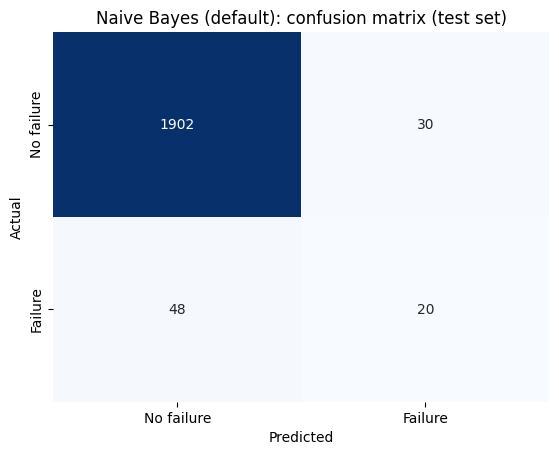

In [105]:
#I put default settings for naive bayes and priors estimated from the training set

from sklearn.naive_bayes import GaussianNB

nb_default = GaussianNB()
nb_default.fit(X_train, y_train)

#I check the priors the model learned (they should match the class shares in the training set)
print("Priors [no failure, failure]:", nb_default.class_prior_.round(4))

print(pd.DataFrame({"train": evaluate(nb_default, X_train, y_train),
                    "test": evaluate(nb_default, X_test, y_test)}).round(3))
plot_confusion(nb_default, X_test, y_test, "Naive Bayes (default): confusion matrix (test set)")
results["Naive Bayes (default)"] = evaluate(nb_default, X_test, y_test)

* so the priors are 0.966 / 0.034, as expected.
* on the test set the model catches only 20 of 68 failures (recall 0.294)
* gives 30 false alarms (precision 0.400)
* F2 is **0.311** and PR-AUC **0.353**, much lower than the decision tree (PR-AUC 0.776)
* training and test results are close (train F2 0.412), so the problem is **not overfitting**: the model is too simple for this data, this is UNDERFITTING!

the low PR-AUC is the most important number because it does not depend on the threshold: it measures whether the model gives higher failure probabilities to real failures than to normal records.
- a low value means the probabilities themselves are not good, so changing only the threshold cannot fully fix this model. Below I check the effect of the prior, and then why the probabilities are poor

           default priors (test)  equal priors (test)
accuracy                   0.961                0.855
recall                     0.294                0.824
precision                  0.400                0.168
F2                         0.311                0.462
PR-AUC                     0.353                0.353


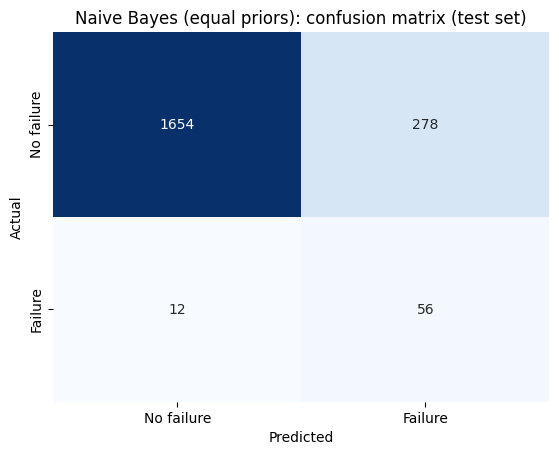

In [106]:
#prior pushes every prediction towards "no failure", because it starts from 96.6% vs 3.4%
#to see its effect, I force equal priors (50% / 50%), for example I tell the model not to favour the majority class
nb_equal = GaussianNB(priors=[0.5, 0.5]).fit(X_train, y_train)
print(pd.DataFrame({"default priors (test)": evaluate(nb_default, X_test, y_test),
                    "equal priors (test)": evaluate(nb_equal, X_test, y_test)}).round(3))
plot_confusion(nb_equal, X_test, y_test, "Naive Bayes (equal priors): confusion matrix (test set)")

with equal priors recall jumps from 0.294 to **0.824 (56 of 68 failures)**, but the false alarms jump from 30 to **278** (precision 0.168). F2 rises to 0.462.

**PR-AUC does not change at all (0.353 in both cases).** changing the prior multiplies the failure odds of every record by the same number, so the *ranking* of the records stays the same: the prior only moves the decision threshold. This shows that the prior and the threshold are two ways to do the same thing, like the class weight in the tree

the prior explains why the default model misses so many failures, but it is not the real limit. The real limit is the quality of the ranking (PR-AUC), which comes from the likelihoods. I'll also check the two assumptions behind them

                  rotational_speed  torque  power  air_temp  process_temp
rotational_speed              1.00   -0.89  -0.81      0.04          0.03
torque                       -0.89    1.00   0.98     -0.04         -0.02
power                        -0.81    0.98   1.00     -0.03         -0.02
air_temp                      0.04   -0.04  -0.03      1.00          0.88
process_temp                  0.03   -0.02  -0.02      0.88          1.00


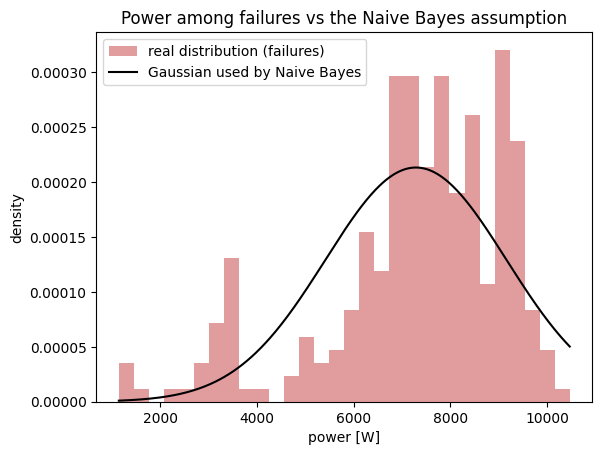

In [107]:
#assumption 1 was independence. naive bayes multiplies the likelihoods as if the features gave independent evidence
#I'll check the correlations inside the "no failure" class the assumption is "independent given the class"

print(X_train[y_train == 0][["rotational_speed", "torque", "power", "air_temp", "process_temp"]].corr().round(2))

#assumption 2 was normal distribution. for the failure class, naive bayes describes power with ONE bell curve (mean theta_, variance var_)
#I draw it over the real distribution of power among failures
failure_power = X_train.loc[y_train == 1, "power"]
power_idx = list(X_train.columns).index("power")
mean_f = nb_default.theta_[1, power_idx]
std_f = np.sqrt(nb_default.var_[1, power_idx])

grid = np.linspace(failure_power.min(), failure_power.max(), 300)
normal_curve = np.exp(-0.5 * ((grid - mean_f) / std_f) ** 2) / (std_f * np.sqrt(2 * np.pi))

plt.hist(failure_power, bins=30, density=True, color="indianred", alpha=0.6, label="real distribution (failures)")
plt.plot(grid, normal_curve, color="black", label="Gaussian used by Naive Bayes")
plt.xlabel("power [W]")
plt.ylabel("density")
plt.title("Power among failures vs the Naive Bayes assumption")
plt.legend()
plt.show()

**I understand from the graph:**

- **Independence is clearly violated:** inside the normal class, torque and power have a correlation of **0.98**, torque and rotational speed **-0.89**, air and process temperature **0.88**. Power is computed from torque and speed, so Naive Bayes counts the same evidence two or three times and becomes over-confident
- **The normal-distribution assumption does not fit the failures:** all failures, power has a separate small group at very low values (about 1,000-4,000 W) and a large group at high values (up to 10,500 W). Naive Bayes describes all of them with one bell curve with its peak around 7,300 W. The low-power group is almost ignored by the curve and the peak lies close to the normal operating range (normal machines have a median of about 6,200 W), so a normal machine and a failing one get similar likelihoods.

this is the opposite of the decision tree. The tree cuts power at two thresholds and isolates both groups; Naive Bayes can only model one peak per class and feature. The same box-plot finding (failures at both extremes) that helped the tree hurts Naive Bayes

In [108]:
#even with poor probabilities, the threshold can still give a better balance between recall and precision
#as for KNN, I choose it with cross-validated probabilities on the training set only
nb_thresholds = [0.01, 0.02, 0.05, 0.10, 0.20, 0.30, 0.50]
proba_cv = cross_val_predict(GaussianNB(), X_train, y_train, cv=cv, method="predict_proba")[:, 1]
rows = []
for t in nb_thresholds:
    pred_cv = (proba_cv >= t).astype(int)
    rows.append({"threshold": t,
                 "recall": recall_score(y_train, pred_cv),
                 "precision": precision_score(y_train, pred_cv, zero_division=0),
                 "F2": fbeta_score(y_train, pred_cv, beta=2)})
nb_thr = pd.DataFrame(rows)
print(nb_thr.round(3))

nb_best_t = float(nb_thr.sort_values("F2", ascending=False).iloc[0]["threshold"])
print("Chosen threshold:", nb_best_t)

#the only use of the test set for this model.
nb_test, nb_cm = evaluate_at_threshold(nb_default, X_test, y_test, nb_best_t)
print(pd.Series(nb_test).round(3))
print("Confusion matrix:\n", nb_cm)
results[f"Naive Bayes (threshold {nb_best_t})"] = nb_test

   threshold  recall  precision     F2
0       0.01   0.919      0.089  0.320
1       0.02   0.893      0.127  0.405
2       0.05   0.771      0.187  0.474
3       0.10   0.661      0.237  0.487
4       0.20   0.583      0.312  0.497
5       0.30   0.494      0.338  0.453
6       0.50   0.413      0.410  0.413
Chosen threshold: 0.2
accuracy     0.949
recall       0.485
precision    0.330
F2           0.444
PR-AUC       0.353
dtype: float64
Confusion matrix:
 [[1865   67]
 [  35   33]]


in cross-validation the best threshold is **0.20**, with F2 = 0.497 (0.413 with the default 0.5). The F2 curve is flat between 0.05 and 0.20 (0.47-0.50). On the test set the model with threshold 0.20 catches **33 of 68 failures (recall 0.485)** with **67 false alarms** (precision 0.330), F2 **0.444**. Lowering the threshold helps, but no threshold makes the model good, because the ranking (PR-AUC 0.353) stays poor.


- Naive Bayes is the weakest model so far (below the decision tree and KNN), and the reason is clear: its two assumptions are both violated here. Correlated features break the independence assumption, and failures at both extremes of power and torque break the normal-distribution assumption
- It is still useful as a lesson for the report: the model with the strongest assumptions about the data is the one that performs worst on this dataset, while the tree, which makes no assumption about the shape of the distributions, performs best.
- I do not tune Naive Bayes further: there is almost nothing to tune (only the prior and a smoothing parameter), and the problem lies in the assumptions, not in the settings.

In [109]:
#running comparison table after Naive Bayes default and best threshold version
pd.DataFrame(results).T.round(3)

,accuracy,recall,precision,F2,PR-AUC
Baseline (always 0),0.966,0.000,0.000,0.000,0.034
Decision Tree (default),0.983,0.735,0.758,0.740,0.566
Decision Tree (tuned),0.985,0.706,0.828,0.727,0.649
Decision Tree (balanced),0.974,0.809,0.579,0.749,0.765
"KNN (k=71, threshold 0.1)",0.954,0.735,0.400,0.630,0.579
Naive Bayes (default),0.961,0.294,0.400,0.311,0.353
Naive Bayes (threshold 0.2),0.949,0.485,0.330,0.444,0.353


PS to myself:
The decision tree is the best model so far, but it has two weaknesses: it overfits (perfect on the training set) and it is unstable, because a small change in the training records can change the first splits and therefore the whole tree.

## 4.5 RANDOM FOREST

A Random Forest is an ensemble of many decision trees that we saw on the course. It adds two sources of randomness, so that the trees make different errors:

1. **Bagging (bootstrap aggregating):** every tree is trained on a bootstrap sample
  - 8,000 records drawn with replacement from the training set.
  - On average each tree sees about 63% of the distinct records; the remaining almost 37% are its out-of-bag (OOB) records.

2. **Random feature subsets:** at every split a tree can choose only among a random subset of the features `max_features`. This prevents all the trees from using the same strongest feature first, so the trees are less correlated.

The final probability is the **average of the trees' votes**. Averaging many trees that each overfit in a different way reduces the variance, while each tree stays as flexible as a single tree. This is why I expect the forest to keep the threshold rules found by the tree but to be more stable.

Like the decision tree, the forest needs no scaling, so I use the unscaled `X_train`.

           train   test
accuracy     1.0  0.990
recall       1.0  0.750
precision    1.0  0.944
F2           1.0  0.782
PR-AUC       1.0  0.878


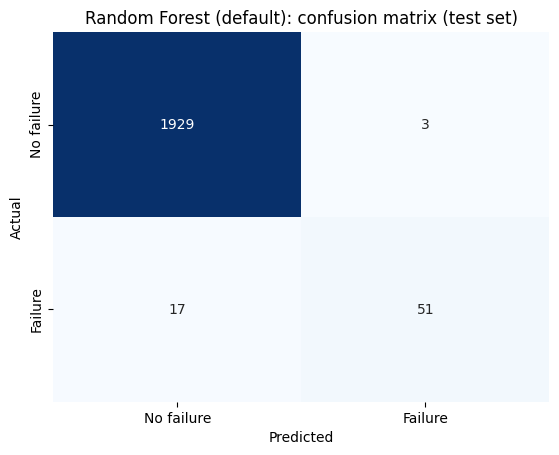

Mean F2 in cross-validation: 0.725


In [110]:
#a first forest with default settings (no depth limit, max_features="sqrt") to compare it with the single unlimited tree.
#n_estimators=200 trees (the choice is checked in the next cell)
#n_jobs=-1 uses all CPU cores, because the trees are independent and can be trained in parallel
#random_state=42 fixes the bootstrap samples and the feature subsets (reproducibility).

from sklearn.ensemble import RandomForestClassifier

rf_default = RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1)
rf_default.fit(X_train, y_train)

print(pd.DataFrame({"train": evaluate(rf_default, X_train, y_train),
                    "test": evaluate(rf_default, X_test, y_test)}).round(3))
plot_confusion(rf_default, X_test, y_test, "Random Forest (default): confusion matrix (test set)")

#the same 5-fold cross-validated F2 used for the other models, for a fair comparison.
from sklearn.model_selection import cross_val_score
rf_default_cv = cross_val_score(RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1),
                                X_train, y_train, scoring=f2_scorer, cv=cv)
print("Mean F2 in cross-validation:", round(rf_default_cv.mean(), 3))


#In the grapg I saw that like the unlimited tree, the default forest is perfect on the training set (so each tree is grown without limits)
#on the test set it catches 51 of 68 failures (recall 0.750)
#with only **3 false alarms (precision 0.944)
#F2 0.782
#different measurement is PR-AUC: 0.878 against 0.566 for the unlimited tree and 0.776 for the best tree so far

- The high PR-AUC means the forest ranks the records much better:
  - failures get clearly higher probabilities than normal records.
  - single unlimited tree gives almost only 0 or 1, while the average of 200 trees gives a smooth probability.

- At the default threshold 0.5 the forest is cautious:
  - high precision,
  - recall lower than the balanced tree
  - cross-validated F2 (0.725) is even slightly below the unlimited tree (0.758).
  - 3% failures, more than half of the trees must vote "failure", which happens only for clear cases.

- So the forest has the right information, but its decision rule must be moved toward the failures: with class weights (grid search below) or with the threshold

   trees  OOB error  OOB PR-AUC
0     25     0.0118      0.8388
1     50     0.0112      0.8663
2    100     0.0111      0.8762
3    150     0.0109      0.8806
4    200     0.0110      0.8828
5    300     0.0111      0.8817
6    400     0.0110      0.8835
7    500     0.0110      0.8843


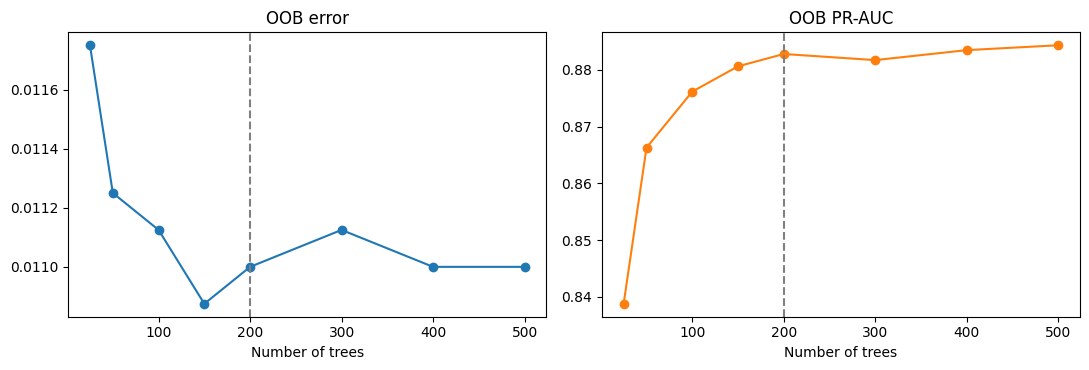

In [111]:
#how many trees are enough? More trees never make the forest overfit more, they only make it slower,so I look for the point where the results stop improving.
#I use the out-of-bag (OOB) records:
#every training record is predicted only by the trees that did NOT see it in their bootstrap sample,
#so the OOB score is a free validation estimate that does not touch the test set.

oob_rows = []
for n in [25, 50, 100, 150, 200, 300, 400, 500]:
    rf_n = RandomForestClassifier(n_estimators=n, random_state=42, n_jobs=-1, oob_score=True)
    rf_n.fit(X_train, y_train)
    oob_proba = rf_n.oob_decision_function_[:, 1]
    oob_rows.append({"trees": n,
                     "OOB error": 1 - rf_n.oob_score_,
                     "OOB PR-AUC": average_precision_score(y_train, oob_proba)})
oob_table = pd.DataFrame(oob_rows)
print(oob_table.round(4))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].plot(oob_table["trees"], oob_table["OOB error"], marker="o")
ax[0].set_title("OOB error")
ax[1].plot(oob_table["trees"], oob_table["OOB PR-AUC"], marker="o", color="tab:orange")
ax[1].set_title("OOB PR-AUC")
for a in ax:
    a.set_xlabel("Number of trees")
    a.axvline(200, color="grey", linestyle="--")
plt.tight_layout()
plt.show()


#OOB error is already stable at about 1.1 from 50 trees(the left plot is zoomed: all values are between 1.09% and 1.18%, so the ups and downs are only one or two records).
#OOB PR-AUC (a better measure for the rare class) increases from 0.839 with 25 trees to 0.883 with 200 trees and then stays flat (0.884 with 500)

#I keep 200 trees for all the forests below, more trees would give the same results and make the grid search slower!!!!!

In [112]:
#hyperparameter tuning with the same grid search, 5 folds and F2 scorer as the decision tree
#- max_depth: None (full trees) or 10 (the best depth of the single tree).
#- min_samples_leaf: larger leaves give smoother probabilities and less overfitting of each tree.
#- max_features: how many features each split can choose from. "sqrt" = 2 of my 8 features, 0.5 = 4 features, None = all 8 (then the trees differ only by their bootstrap samples).
#- class_weight: "balanced_subsample" is the "balanced" weighting of the decision tree, recomputed inside each bootstrap sample (each sample has a slightly different number of failures).
# 36 combinations x 5 folds x 200 trees
rf_grid = {
    "max_depth": [None, 10],
    "min_samples_leaf": [1, 3, 5],
    "max_features": ["sqrt", 0.5, None],
    "class_weight": [None, "balanced_subsample"],
}
rf_search = GridSearchCV(RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1),
                         rf_grid, scoring=f2_scorer, cv=cv)
rf_search.fit(X_train, y_train)

print("Combinations tested:", len(rf_search.cv_results_["params"]), "x 5 folds")
print("Best parameters:", rf_search.best_params_)
print("Best mean F2 in cross-validation:", round(rf_search.best_score_, 3))

# Why: the best result for each option, to see which setting matters most.
rf_cv_table = pd.DataFrame(rf_search.cv_results_)
# I read each option from the "params" dictionaries and write it as text, so that the option None
# is shown as "None" (otherwise pandas treats it as a missing value and groupby drops it).
for name in ["class_weight", "max_features", "min_samples_leaf"]:
    option = rf_cv_table["params"].map(lambda d: str(d[name])).rename(name)
    print(rf_cv_table.groupby(option)["mean_test_score"].max().round(3), "\n")


#the best forest uses class_weight = "balanced_subsample", max_features = 0.5 (4 features per split), min_samples_leaf = 5 and no depth limit,
#with a mean cross-validated F2 of 0.807,
#the highest of all models (best tree: 0.773)

#- class weights are the most important setting: the best forest without weights reaches 0.783.
#- max_features = 0.5 is better than all 8 features (None, 0.801) and much better than "sqrt" (0.773). With only 2 candidate features, many splits cannot use power or temp_diff, which carry the failure rules; with all 8 features the trees become too similar to each other; with 4 candidates the trees stay accurate but still differ from each other.
#- min_samples_leaf = 5 works better than 1: each tree overfits less, and the leaves give more reliable probabilities

Combinations tested: 36 x 5 folds
Best parameters: {'class_weight': 'balanced_subsample', 'max_depth': None, 'max_features': 0.5, 'min_samples_leaf': 5}
Best mean F2 in cross-validation: 0.803
class_weight
None                  0.783
balanced_subsample    0.803
Name: mean_test_score, dtype: float64 

max_features
0.5     0.803
None    0.801
sqrt    0.785
Name: mean_test_score, dtype: float64 

min_samples_leaf
1    0.783
3    0.792
5    0.803
Name: mean_test_score, dtype: float64 



           train   test
accuracy   0.997  0.990
recall     0.996  0.838
precision  0.922  0.864
F2         0.980  0.843
PR-AUC     0.993  0.871


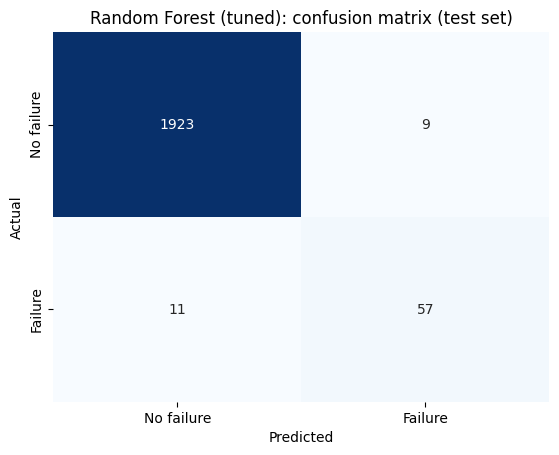

In [113]:
#forest chosen by cross-validation, retrained on the whole training set, evaluated once on the test set
rf_best = rf_search.best_estimator_
print(pd.DataFrame({"train": evaluate(rf_best, X_train, y_train),
                    "test": evaluate(rf_best, X_test, y_test)}).round(3))
plot_confusion(rf_best, X_test, y_test, "Random Forest (tuned): confusion matrix (test set)")


#the tuned forest catches:
#57 of 68 failures (recall 0.838)
#with only 9 false alarms (precision 0.864)
#F2 is 0.843
#PR-AUC 0.871


#compared with the best tree, the forest catches one failure more and raises 32 fewer false alarms
#this is exactly the effect expected from averaging: the balanced tree had to accept many false alarms to reach high recall, while the forest reaches the same recall with high precision.
#train F2 (0.980) is still higher than the test F2, but the gap is smaller than for the unlimited models (1.000).

In [114]:
#for KNN and Naive Bayes the threshold 0.5 was a bad choice, so I check it for the forest too with the same method:
#cross-validated probabilities on the training set only
rf_proba_cv = cross_val_predict(RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1,
                                                       **rf_search.best_params_),
                                X_train, y_train, cv=cv, method="predict_proba")[:, 1]
rows = []
for t in [0.20, 0.30, 0.40, 0.45, 0.50, 0.55, 0.60, 0.70]:
    pred_cv = (rf_proba_cv >= t).astype(int)
    rows.append({"threshold": t,
                 "recall": recall_score(y_train, pred_cv),
                 "precision": precision_score(y_train, pred_cv, zero_division=0),
                 "F2": fbeta_score(y_train, pred_cv, beta=2)})
print(pd.DataFrame(rows).round(3))

#the cross-validated F2 is highest at 0.50 (0.807) almost equal at 0.40 (0.805),
#lower for smaller or larger thresholds (0.787 at 0.30, 0.777 at 0.60)

#I keep the default threshold 0.5:
#class weights already move the forest's probabilities toward the failures,
#so lowering the threshold is not needed (unlike KNN and Naive Bayes)!!!
#table also shows the business trade-off:
#at 0.30 recall rises to 0.871
#but precision falls to 0.569.


#I will come back to this in the evaluation phase, when I choose the final threshold from a cost ratio!!!!!


   threshold  recall  precision     F2
0       0.20   0.908      0.426  0.741
1       0.30   0.863      0.567  0.782
2       0.40   0.819      0.730  0.800
3       0.45   0.804      0.787  0.801
4       0.50   0.793      0.846  0.803
5       0.55   0.764      0.866  0.782
6       0.60   0.749      0.910  0.777
7       0.70   0.679      0.948  0.720


                  Decision Tree (tuned)  Random Forest (tuned)
rotational_speed                  0.077                  0.229
tool_wear                         0.133                  0.227
torque                            0.050                  0.207
power                             0.386                  0.192
temp_diff                         0.293                  0.082
air_temp                          0.006                  0.032
process_temp                      0.014                  0.023
type                              0.042                  0.008


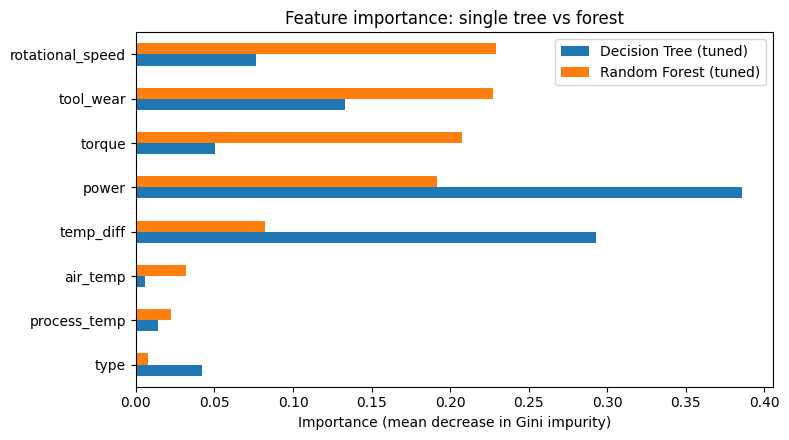

In [115]:
#compare which features the single tree and the forest use.
#importance = mean decrease of Gini impurity over all splits (and over all trees for the forest), normalised to sum to 1

importance_compare = pd.DataFrame({
    "Decision Tree (tuned)": pd.Series(dt_best.feature_importances_, index=X_train.columns),
    "Random Forest (tuned)": pd.Series(rf_best.feature_importances_, index=X_train.columns),
}).sort_values("Random Forest (tuned)")
print(importance_compare.sort_values("Random Forest (tuned)", ascending=False).round(3))

importance_compare.plot.barh(figsize=(8, 4.5))
plt.xlabel("Importance (mean decrease in Gini impurity)")
plt.title("Feature importance: single tree vs forest")
plt.tight_layout()
plt.show()

#tree concentrated its importance on power (0.386) and temp_diff (0.293)
#forest spreads it: tool_wear 0.230, rotational_speed 0.227, torque 0.202, power 0.197, temp_diff 0.081
#air and process temperatures and type remain the least important.

- This is the effect of the random feature subsets: when power is not among the 4 candidates of a split, the tree uses torque or rotational speed, which carry almost the same information (power = torque x speed, correlation 0.98 with torque).
  - The importance is then shared among correlated features, so it must not be read as power is less important for the forest.

- Tool wear gains importance because the forest also learns the overstrain rule (tool wear x torque), which needs several splits on tool wear.

- Impurity importance is computed on the training data and is biased by correlated features. For the final model I will also use permutation importance and SHAP on the test set.

In [116]:
#error analysis

#which failures does the forest miss? I use the failure-mode columns that I removed from the features
#this is NOT data leakage: the model is already trained and the modes are only used afterwards to explain its errors. (like maintenance times we are reading reports)


test_pred = pd.Series(rf_best.predict(X_test), index=X_test.index)
test_failures = y_test[y_test == 1].index
failure_modes = df.loc[test_failures, modes]       # same row index as X_test, so the rows match
caught = test_pred[test_failures] == 1

per_mode = pd.DataFrame({
    "failures in test": failure_modes.sum(),
    "caught": failure_modes[caught].sum(),
})
no_mode = failure_modes.sum(axis=1) == 0
per_mode.loc["no mode"] = [no_mode.sum(), (no_mode & caught).sum()]
print(per_mode)   # a failure can have two modes, so the column sums are larger than 68

#I looked at the missed failures and the false alarms in detail in there:
print("\nMissed failures:")
print(df.loc[test_failures[~caught.values], modes].join(X_test[["tool_wear", "torque", "rotational_speed", "temp_diff", "power"]]).round(1))
print("\nFalse alarms:")
print(X_test[(test_pred == 1) & (y_test == 0)][["tool_wear", "torque", "rotational_speed", "temp_diff", "power"]].round(1))

#how many records in the whole dataset have tool wear between 200 and 240 min, and how many of them are TWF?
in_window = df["Tool wear [min]"].between(200, 240)
print("\nRecords with tool wear 200-240 min:", in_window.sum(), "| of which TWF:", df.loc[in_window, "TWF"].sum())

         failures in test  caught
TWF                    10       1
HDF                    29      29
PWF                    13      13
OSF                    16      16
RNF                     0       0
no mode                 2       0

Missed failures:
      TWF  HDF  PWF  OSF  RNF  tool_wear  torque  rotational_speed  temp_diff  \
9174    1    0    0    0    0        200    25.6              1871       11.1   
2671    1    0    0    0    0        221    41.9              1399        9.6   
2864    1    0    0    0    0        246    47.6              1380        8.8   
3695    1    0    0    0    0        207    37.3              1530        9.1   
7087    1    0    0    0    0        217    30.5              1648        9.7   
2941    1    0    0    0    0        203    19.8              1996        8.9   
9015    0    0    0    0    0        210    49.7              1431       10.9   
7849    1    0    0    0    0        222    47.9              1374       11.4   
8506    0    0 

- The forest catches every heat dissipation, power and overstrain failure. These three modes are defined by deterministic thresholds on the sensors, and the forest has learned them.

- 9 of the 11 missed failures are tool wear failures the other 2 have no failure mode

- The reason is in the data generation: the tool is replaced or fails at a random wear time between 200 and 240 minutes. In the whole dataset 790 records are in this window, but only 43 of them are TWF (5.4%). No sensor value tells which records in the window will fail, so no model can predict TWF well with these features.

- The 9 false alarms are records very close to the failure rules:
  - all of them have a low rotational speed (1,220-1,430 rpm)
  - a high torque (47-70 Nm);
    - several also have a temperature difference just above the HDF limit (8.6-9.0 K)
    - a tool wear above 200 minutes.
They are almost failures because of that a maintenance engineer would probably want to inspect anyway!!!

I'll use these informations until that point on the report I'll also want to add myself this note: the remaining errors are mostly irreducible with these features they come from random events, not from a weak model.
- this sets a realistic upper limit for every model, and it is an important point for the conclusions:
  - in a real plant, tool wear failures would be handled by a planned tool replacement before 200 minutes, not by a classifier.

In [117]:
#I want to store the test results of both forests in the comparison table for report
results["Random Forest (default)"] = evaluate(rf_default, X_test, y_test)
results["Random Forest (tuned)"] = evaluate(rf_best, X_test, y_test)
pd.DataFrame(results).T.round(3)

,accuracy,recall,precision,F2,PR-AUC
Baseline (always 0),0.966,0.000,0.000,0.000,0.034
Decision Tree (default),0.983,0.735,0.758,0.740,0.566
Decision Tree (tuned),0.985,0.706,0.828,0.727,0.649
Decision Tree (balanced),0.974,0.809,0.579,0.749,0.765
"KNN (k=71, threshold 0.1)",0.954,0.735,0.400,0.630,0.579
Naive Bayes (default),0.961,0.294,0.400,0.311,0.353
Naive Bayes (threshold 0.2),0.949,0.485,0.330,0.444,0.353
Random Forest (default),0.990,0.750,0.944,0.782,0.878
Random Forest (tuned),0.990,0.838,0.864,0.843,0.871


FINAL COMMENT OF MYSELF:

In the random forest, tuned forest is the best model so far on every selection metric it keeps the strength of the tree (threshold rules) and removes most of its false alarms by averaging 200 different trees. Its remaining misses are almost all tool wear failures, which are random in this dataset.

**Next step:** Gradient Boosting. A Random Forest builds its trees **independently** and averages them (it reduces variance). Boosting builds the trees **one after another**, each one focusing on the errors of the previous ones (it reduces bias). It is often the strongest model on tabular data, so it is the natural last candidate.

#4.6 Gradient Boosting

this is the model of Random Forest and boosting both combine many trees, but in opposite ways:


| | Random Forest (bagging) | Gradient Boosting |
| --- | --- | --- |
| How the trees are built | independently, in parallel | one after another, in sequence |
| What each tree learns | the target, from its own bootstrap sample | the **errors** of all previous trees |
| Typical trees | deep (each one overfits) | shallow (each one is weak) |
| What it reduces | variance | bias |

How Gradient Boosting works for classification:

1. it starts from a constant prediction: the failure rate (3.4%) for every record.
2. for each record it computes the residual = true label - predicted probability (technically the negative gradient of the log-loss).
    - failures that the model still predicts as "no failure" get large residuals.
3. small regression tree is trained to predict these residuals, so the new tree focuses on the records that are still wrong
4. tree's output is added to the model, multiplied by the learning rate (for example 0.1), so each tree corrects only a small part of the error.

and step 2-4 are repeated `n_estimators` times.

this is the same idea as AdaBoost from the lecture (give more attention to the misclassified records), but instead of re-weighting the records it fits the residuals directly.

           train   test
accuracy   0.995  0.992
recall     0.860  0.779
precision  0.991  0.981
F2         0.883  0.813
PR-AUC     0.955  0.904


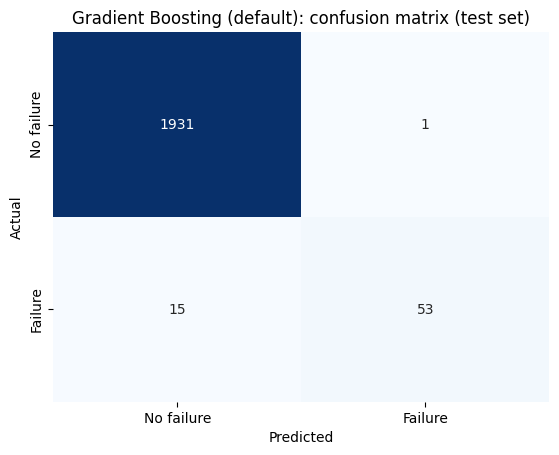

Mean F2 in cross-validation: 0.782


In [118]:
#first boosting model with the default settings:
#100 trees of depth 3,
#learning rate 0.1
#random_state=42 makes the result reproducible (like the other tree models it needs no scaling)

from sklearn.ensemble import GradientBoostingClassifier

gb_default = GradientBoostingClassifier(random_state=42)
gb_default.fit(X_train, y_train)

print(pd.DataFrame({"train": evaluate(gb_default, X_train, y_train),
                    "test": evaluate(gb_default, X_test, y_test)}).round(3))
plot_confusion(gb_default, X_test, y_test, "Gradient Boosting (default): confusion matrix (test set)")

#the same 5-fold cross-validated F2 used for the other models
gb_default_cv = cross_val_score(GradientBoostingClassifier(random_state=42),
                                X_train, y_train, scoring=f2_scorer, cv=cv)
print("Mean F2 in cross-validation:", round(gb_default_cv.mean(), 3))



#default boosting model is not perfect on the training set (train recall 0.860),
#unlike the unlimited tree and the default forest: 100 shallow trees with a small learning rate cannot memorise the data
#on the test set it catches:
#53 of 68 failures (recall 0.779)
#1 false alarm (precision 0.981)
#F2 0.813
#PR-AUC 0.904 (the highest PR-AUC so far) and its cross-validated F2 is 0.782.

#like the default forest, the default boosting model ranks the records very well but is cautious at the threshold 0.5 (very high precision, lower recall)
#tuning should push it toward more recall!!!!

In [121]:
#hyperparameter tuning with the same grid search, 5 folds and F2 scorer as the other models
# - n_estimators: number of boosting rounds (trees added one after another)
# - learning_rate: how much each new tree corrects. Small = slow, careful learning, needs more trees
# - max_depth: depth of each tree. Depth 2-3 = weak learners; depth 5 = trees that capture interactions
#   between up to 5 features (for example tool wear x torque for overstrain)
# n_jobs=-1: the 27 x 5 fits run in parallel (boosting itself is sequential)

gb_grid = {
    "n_estimators": [100, 200, 300],
    "learning_rate": [0.05, 0.1, 0.2],
    "max_depth": [2, 3, 5],
}
gb_search = GridSearchCV(GradientBoostingClassifier(random_state=42), gb_grid,
                         scoring=f2_scorer, cv=cv, n_jobs=-1)
gb_search.fit(X_train, y_train)

print("Combinations tested:", len(gb_search.cv_results_["params"]), "x 5 folds")
print("Best parameters:", gb_search.best_params_)
print("Best mean F2 in cross-validation:", round(gb_search.best_score_, 3))

#5 best combinations, to see whether the winner is clearly better than the others
gb_cv_table = pd.DataFrame(gb_search.cv_results_)
print(gb_cv_table.sort_values("mean_test_score", ascending=False)
      [["params", "mean_test_score", "std_test_score"]].head(5).round(3).to_string())

#best result for each value of each hyperparameter:
for name in ["n_estimators", "learning_rate", "max_depth"]:
    option = gb_cv_table["params"].map(lambda d: str(d[name])).rename(name)
    print(gb_cv_table.groupby(option)["mean_test_score"].max().round(3), "\n")

Combinations tested: 27 x 5 folds
Best parameters: {'learning_rate': 0.2, 'max_depth': 5, 'n_estimators': 200}
Best mean F2 in cross-validation: 0.801
                                                         params  mean_test_score  std_test_score
25  {'learning_rate': 0.2, 'max_depth': 5, 'n_estimators': 200}            0.801           0.047
14  {'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 300}            0.800           0.037
24  {'learning_rate': 0.2, 'max_depth': 5, 'n_estimators': 100}            0.799           0.051
26  {'learning_rate': 0.2, 'max_depth': 5, 'n_estimators': 300}            0.797           0.046
23  {'learning_rate': 0.2, 'max_depth': 3, 'n_estimators': 300}            0.796           0.044
n_estimators
100    0.799
200    0.801
300    0.800
Name: mean_test_score, dtype: float64 

learning_rate
0.05    0.793
0.1     0.800
0.2     0.801
Name: mean_test_score, dtype: float64 

max_depth
2    0.765
3    0.800
5    0.801
Name: mean_test_score, dtype: float6

best combination looks:
- learning_rate = 0.2,
- max_depth = 5,
- n_estimators = 200, with a mean cross-validated F2 of 0.800.

But the top combinations are practically tied:
- learning_rate 0.1
- depth 3 and
- 300 trees also scores 0.800 and the differences < 0.01 are much smaller than the standard deviation between the folds (about 0.04-0.05).

- max_depth = 2 is clearly worse (0.765): trees with only 2 levels cannot represent the failure rules that combine two conditions. for example:
  - HDF = low speed and small temperature difference and three-way interactions such as overstrain.
  - number of trees and the learning rate compensate each other: a smaller learning rate needs more trees.

so I keep the combination chosen by cross-validation, as for all the other models, so that the selection procedure is the same. Its cross-validated F2 (0.800) is very close to the Random Forest (0.807).

           train   test
accuracy     1.0  0.990
recall       1.0  0.824
precision    1.0  0.889
F2           1.0  0.836
PR-AUC       1.0  0.832


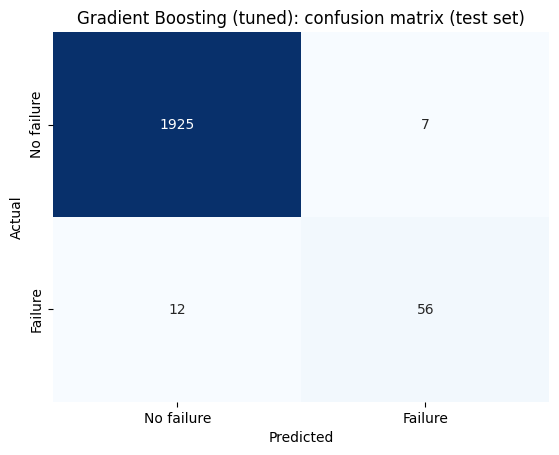

In [122]:
#boosting model chosen by cross-validation, retrained on the whole training set, evaluated once on the test set
gb_best = gb_search.best_estimator_
print(pd.DataFrame({"train": evaluate(gb_best, X_train, y_train),
                    "test": evaluate(gb_best, X_test, y_test)}).round(3))
plot_confusion(gb_best, X_test, y_test, "Gradient Boosting (tuned): confusion matrix (test set)")

 I understand from the (test set): the tuned boosting model catches:
- 56 of 68 failures (recall 0.824)
- 7 false alarms (precision 0.889)
- F2 0.836
This is almost the same as the tuned forest (57 caught, 9 false alarms, F2 0.843): one failure less and two false alarms less.

Two warning signs:

- Training set is now perfect (all metrics 1.000): 200 trees of depth 5 with a high learning rate end up memorising the training data.
- PR-AUC drops from 0.904 (default) to 0.832
- Tuned model is better at the 0.5 threshold, but its probabilities are pushed to almost 0 or 1, so it ranks the records less finely.

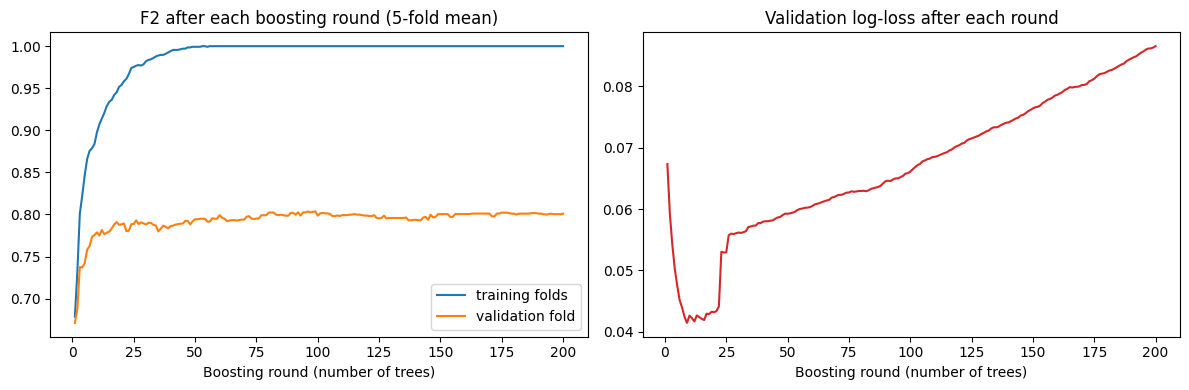

Round with the lowest validation log-loss: 9
round  10 | train F2 0.898 | validation F2 0.779 | validation log-loss 0.0426
round  25 | train F2 0.975 | validation F2 0.789 | validation log-loss 0.0529
round  50 | train F2 0.999 | validation F2 0.794 | validation log-loss 0.0592
round 100 | train F2 1.000 | validation F2 0.799 | validation log-loss 0.0661
round 150 | train F2 1.000 | validation F2 0.800 | validation log-loss 0.0764
round 200 | train F2 1.000 | validation F2 0.801 | validation log-loss 0.0865


In [123]:
#boosting adds one tree per round, so I can follow the model round by round with staged_predict_proba
#I do it inside the 5 cross-validation folds (never on the test set): for each fold I train the selected model and record, after every round
#the F2 on the training folds and the F2 and log-loss on the validation fold.
#log-loss measures the quality of the probabilities (it punishes confident wrong predictions), F2 only measures the decisions at the 0.5 threshold

from sklearn.metrics import log_loss

n_rounds = gb_search.best_params_["n_estimators"]
train_f2 = np.zeros(n_rounds)
valid_f2 = np.zeros(n_rounds)
valid_loss = np.zeros(n_rounds)
for train_idx, valid_idx in cv.split(X_train, y_train):
    X_tr, y_tr = X_train.iloc[train_idx], y_train.iloc[train_idx]
    X_va, y_va = X_train.iloc[valid_idx], y_train.iloc[valid_idx]
    model = GradientBoostingClassifier(random_state=42, **gb_search.best_params_).fit(X_tr, y_tr)
    for i, (p_tr, p_va) in enumerate(zip(model.staged_predict_proba(X_tr), model.staged_predict_proba(X_va))):
        train_f2[i] += fbeta_score(y_tr, p_tr[:, 1] >= 0.5, beta=2) / 5      # mean over the 5 folds
        valid_f2[i] += fbeta_score(y_va, p_va[:, 1] >= 0.5, beta=2) / 5
        valid_loss[i] += log_loss(y_va, p_va[:, 1]) / 5

rounds = np.arange(1, n_rounds + 1)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(rounds, train_f2, label="training folds")
ax[0].plot(rounds, valid_f2, label="validation fold")
ax[0].set_title("F2 after each boosting round (5-fold mean)")
ax[0].legend()
ax[1].plot(rounds, valid_loss, color="tab:red")
ax[1].set_title("Validation log-loss after each round")
for a in ax:
    a.set_xlabel("Boosting round (number of trees)")
plt.tight_layout()
plt.show()

print("Round with the lowest validation log-loss:", valid_loss.argmin() + 1)
for r in [10, 25, 50, 100, 150, n_rounds]:
    print(f"round {r:3d} | train F2 {train_f2[r-1]:.3f} | validation F2 {valid_f2[r-1]:.3f} | validation log-loss {valid_loss[r-1]:.4f}")

my comments of the plot: the left plot shows the learning process of boosting, one tree at a time. With depth-5 trees and learning rate 0.2, the first tree alone already reaches F2 of about 0.68 (it captures the strongest power and heat rules). Every new tree corrects part of the remaining residuals. The gap between the training curve (blue) and the validation curve (orange) is the OVERFITTING!!


- The validation F2 rises from about 0.68 to 0.78 after 10 rounds and then grows only slowly, to 0.80 at 150-200 rounds.
- The training F2 reaches 1.0 after about 50 rounds: from there on the model is perfect on the training folds, and every new tree only fits the training records more closely.
- The validation log-loss (right) is lowest at round 9 and then increases steadily (0.043 -> 0.087 at round 200). The decisions at 0.5 stay good (flat F2), but the probabilities become more and more extreme and overconfident: this is overfitting of the probabilities.


NOTES FOR MY REPORT IN THAT PART:
- This explains the lower PR-AUC of the tuned model: the decisions at 0.5 are still good (flat F2), but the probabilities are overconfident.
- It is a key difference with the Random Forest: adding trees to a forest never makes it overfit more (the OOB curve was flat), while adding rounds to boosting does, because each round fits the training errors more closely. For boosting, the number of trees is a real tuning parameter (or early stopping is used)

In [124]:
#the threshold check, with cross-validated probabilities on the training set only (as for the other models)

gb_proba_cv = cross_val_predict(GradientBoostingClassifier(random_state=42, **gb_search.best_params_),
                                X_train, y_train, cv=cv, method="predict_proba", n_jobs=-1)[:, 1]
rows = []
for t in [0.10, 0.20, 0.30, 0.40, 0.50, 0.60]:
    pred_cv = (gb_proba_cv >= t).astype(int)
    rows.append({"threshold": t,
                 "recall": recall_score(y_train, pred_cv),
                 "precision": precision_score(y_train, pred_cv, zero_division=0),
                 "F2": fbeta_score(y_train, pred_cv, beta=2)})
print(pd.DataFrame(rows).round(3))

#GradientBoostingClassifier has no class_weight equivalent is to give every record a weight
#with compute_sample_weight("balanced") (failures about 28 times heavier, as for the balanced tree) and pass it to fit()
from sklearn.utils.class_weight import compute_sample_weight
weights = compute_sample_weight("balanced", y_train)
gb_weighted = GradientBoostingClassifier(random_state=42, **gb_search.best_params_)
gb_weighted.fit(X_train, y_train, sample_weight=weights)
print(pd.Series(evaluate(gb_weighted, X_test, y_test), name="weighted, test").round(3))

# - Threshold: the cross-validated F2 is almost the same for every threshold between 0.1 and 0.6 (0.801-0.809).
#the boosting probabilities are almost always close to 0 or 1, so moving the threshold changes the decision for very few records. I keep 0.5
# - Balanced weights do not help: on the test set recall falls to 0.765 (52 caught).
#with boosting, the residuals of the missed failures are already large,
#so the model already concentrates on them; extra weights mainly make each tree overfit the few failures

#so for boosting, neither the threshold nor the class weights change the result much, model is left as selected by cross-validation

   threshold  recall  precision     F2
0        0.1   0.801      0.844  0.809
1        0.2   0.786      0.862  0.800
2        0.3   0.782      0.883  0.801
3        0.4   0.782      0.902  0.804
4        0.5   0.779      0.909  0.802
5        0.6   0.779      0.921  0.804
accuracy     0.990
recall       0.765
precision    0.912
F2           0.790
PR-AUC       0.853
Name: weighted, test, dtype: float64


                  Decision Tree (tuned)  Random Forest (tuned)  \
power                             0.386                  0.192   
temp_diff                         0.293                  0.082   
tool_wear                         0.133                  0.227   
rotational_speed                  0.077                  0.229   
torque                            0.050                  0.207   
type                              0.042                  0.008   
air_temp                          0.006                  0.032   
process_temp                      0.014                  0.023   

                  Gradient Boosting (tuned)  
power                                 0.303  
temp_diff                             0.237  
tool_wear                             0.174  
rotational_speed                      0.117  
torque                                0.067  
type                                  0.039  
air_temp                              0.035  
process_temp                         

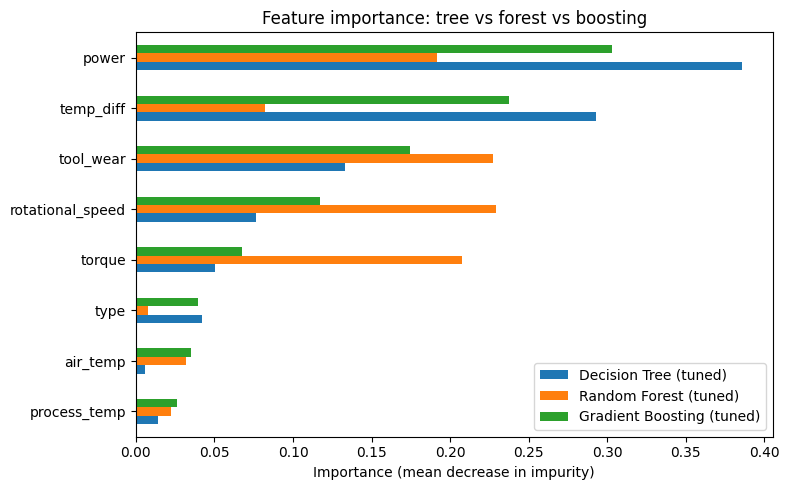

         failures in test  caught (Random Forest)  caught (Gradient Boosting)
TWF                    10                       1                           3
HDF                    29                      29                          28
PWF                    13                      13                          13
OSF                    16                      16                          14
RNF                     0                       0                           0
no mode                 2                       0                           0


In [128]:
#which features each tree model uses (impurity-based importance of the three tuned tree models)

importance_compare["Gradient Boosting (tuned)"] = pd.Series(gb_best.feature_importances_, index=X_train.columns)
print(importance_compare.sort_values("Gradient Boosting (tuned)", ascending=False).round(3))
importance_compare.sort_values("Gradient Boosting (tuned)").plot.barh(figsize=(8, 5))
plt.xlabel("Importance (mean decrease in impurity)")
plt.title("Feature importance: tree vs forest vs boosting")
plt.tight_layout()
plt.show()

#same error analysis by failure mode as for the Random Forest (modes used only after training)
gb_pred = pd.Series(gb_best.predict(X_test), index=X_test.index)
gb_caught = gb_pred[test_failures] == 1
per_mode["caught (Gradient Boosting)"] = list(failure_modes[gb_caught].sum()) + [(no_mode & gb_caught).sum()]
per_mode = per_mode.rename(columns={"caught": "caught (Random Forest)"})
print(per_mode)

#- boosting puts most of the importance on power (0.30) and temp_diff (0.24), like the single tree.
#boosting builds its trees on all the features (no random subsets),
#so it uses the most informative feature directly instead of sharing the importance among correlated features as the forest does

#- by failure mode, the two ensembles behave in almost the same way: both catch all 13 power failures;
#Random Forest catches 29/29 heat dissipation and 16/16 overstrain failures, boosting 28/29 and 14/16;
#boosting catches 3 of the 10 tool wear failures, the forest only 1.
#both miss the 2 failures without a mode


#the two ensembles learned the same failure physics and miss the same kind of failures.
#remaining errors depend on the data, not on the choice between bagging and boosting.

In [127]:
#store the test results of both boosting models in the comparison table as usual
results["Gradient Boosting (default)"] = evaluate(gb_default, X_test, y_test)
results["Gradient Boosting (tuned)"] = evaluate(gb_best, X_test, y_test)
pd.DataFrame(results).T.round(3)

,accuracy,recall,precision,F2,PR-AUC
Baseline (always 0),0.966,0.000,0.000,0.000,0.034
Decision Tree (default),0.983,0.735,0.758,0.740,0.566
Decision Tree (tuned),0.985,0.706,0.828,0.727,0.649
Decision Tree (balanced),0.974,0.809,0.579,0.749,0.765
"KNN (k=71, threshold 0.1)",0.954,0.735,0.400,0.630,0.579
Naive Bayes (default),0.961,0.294,0.400,0.311,0.353
Naive Bayes (threshold 0.2),0.949,0.485,0.330,0.444,0.353
Random Forest (default),0.990,0.750,0.944,0.782,0.878
Random Forest (tuned),0.990,0.838,0.864,0.843,0.871
Gradient Boosting (default),0.992,0.779,0.981,0.813,0.904


##5. Evaluation